# World Economic Data from Wikipedia: scrape, clean, analyze, visualize

**Author:** Arun Kumar Prabhakaran  
**Date:** 2026-11-01

**Question:** how do the world's 15 largest economies compare on output, trade, macro stability, poverty/inequality and social outcomes?

**Pipeline**
1. **Scrape** the Wikipedia "List of countries by …" pages (HTML is cached in `data/raw/`, so re-runs don't hit Wikipedia).
2. **Clean** footnote markers, units, symbols and country-name variants; keep the source page and data year of every value.
3. **Analyze** rankings, derived trade metrics, correlations, group comparisons and a simple two-index scorecard.
4. **Visualize** the comparison (a snapshot, so bar/dot/scatter/heatmap forms, no time series).
5. **Conclude**, with caveats.

**Scope:** top 15 economies by nominal GDP (IMF 2026 estimate), taken from Wikipedia rather than hard-coded. Each indicator is the latest value Wikipedia shows; the data year differs by indicator and is recorded in `data/clean/indicator_provenance.csv`.

## 1. Setup

In [1]:
# Author: Arun Kumar Prabhakaran
# Date: 2026-11-01
import io
import re
import sys
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
CLEAN_DIR = ROOT / "data" / "clean"
FIG_DIR = ROOT / "figures"
for d in (RAW_DIR, CLEAN_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

WIKI = "https://en.wikipedia.org/wiki/"
HEADERS = {"User-Agent": "wiki-economy-analysis/0.1 (personal educational project; python-requests)"}
WIKI_API = "https://en.wikipedia.org/w/api.php"
IN_BROWSER = sys.platform == "emscripten"  # Pyodide / JupyterLite: the browser blocks cross-origin /wiki/ page fetches
N_COUNTRIES = 15
NOT_COUNTRIES = {"World", "European Union", "Euro area", "Eurozone"}

## 2. Scrape

Fetching is cached: a page is downloaded once and then read from `data/raw/`. Tables are parsed with `pandas.read_html`; multi-level headers are flattened to `"Group | Column"`.

In [2]:
def get_with_retry(url, attempts=5, **kwargs):
    # back off and retry when Wikipedia answers 429 Too Many Requests
    for attempt in range(attempts):
        resp = requests.get(url, timeout=30, **kwargs)
        if resp.status_code != 429:
            break
        wait = float(resp.headers.get("Retry-After", 5 * (attempt + 1)))
        print(f"429 from Wikipedia, waiting {wait:.0f}s before retrying")
        time.sleep(wait)
    resp.raise_for_status()
    return resp


def fetch_page(title, delay=1.0):
    path = RAW_DIR / f"{title}.html"
    if path.exists():
        return path.read_text(encoding="utf-8")
    if IN_BROWSER:
        # The API sends CORS headers when asked with origin=*, and returns the same rendered article HTML.
        # No custom headers here: a browser would turn them into a CORS preflight.
        resp = get_with_retry(WIKI_API, params={"action": "parse", "page": title, "prop": "text", "format": "json",
                                                "formatversion": 2, "redirects": 1, "origin": "*"})
        html = resp.json()["parse"]["text"]
    else:
        html = get_with_retry(WIKI + title, headers=HEADERS).text
    path.write_text(html, encoding="utf-8")
    time.sleep(delay)  # be polite to Wikipedia
    return html


def flatten_columns(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [" | ".join(dict.fromkeys(map(str, c))) for c in df.columns]
    else:
        df.columns = [str(c) for c in df.columns]
    return df


_tables = {}


def page_tables(title):
    if title not in _tables:
        html = fetch_page(title)
        _tables[title] = [flatten_columns(t) for t in pd.read_html(io.StringIO(html), flavor="lxml")]
    return _tables[title]

## 3. Cleaning helpers

Wikipedia cells carry footnote markers (`[1]`, `[n 1]`), trailing `*`, thousands separators, unicode minus signs, `%`/`$` symbols and placeholders such as `–` or `—N/a`. The country column is inconsistent too ("United States of America", "USA", "China[n 1]", "Japan *").

In [3]:
ALIASES = {
    "United States of America": "United States",
    "USA": "United States",
    "US": "United States",
    "Korea, South": "South Korea",
    "Republic of Korea": "South Korea",
    "Russian Federation": "Russia",
    "People's Republic of China": "China",
    "Mainland China": "China",
}


def clean_country(value):
    s = re.sub(r"\[.*?\]", "", str(value)).replace("\xa0", " ")
    s = re.sub(r"[\*†‡]+\s*$", "", s)
    s = re.sub(r"\s+", " ", s).strip()
    return ALIASES.get(s, s)


def to_num(value):
    # first number in the cell, or NaN for placeholders like "–" / "—N/a"
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float, np.number)):
        return float(value)
    s = re.sub(r"\[.*?\]", "", str(value)).replace("\xa0", " ")
    s = s.replace("−", "-").replace("–", "-").replace("—", "-")
    m = re.search(r"-?\d[\d,]*\.?\d*", s)
    return float(m.group().replace(",", "")) if m else np.nan


def to_year(value):
    if pd.isna(value):
        return np.nan
    m = re.search(r"(?<!\d)(19|20)\d{2}(?!\d)", re.sub(r"\[.*?\]", "", str(value)))
    return float(m.group()) if m else np.nan


def clean_text(value):
    if pd.isna(value):
        return np.nan
    return re.sub(r"\s+", " ", re.sub(r"\[.*?\]", "", str(value)).replace("\xa0", " ")).strip()


assert clean_country("China[n 1]") == "China" and clean_country("Japan *") == "Japan"
assert to_num("–1,294,794") == -1294794 and to_num("+0.89%") == 0.89 and np.isnan(to_num("—N/a"))
assert to_year("2025[3]") == 2025 and to_year("2020.0") == 2020

### Indicator registry

Each indicator is declared once: the Wikipedia page, a regex for the value column, how to find the data year, and a unit scale. The table is chosen by **column names**, not by position, so a reshuffled page layout doesn't silently pick the wrong table.

* `year="header"`: year is read from the value column's header, e.g. `IMF (2026)`.
* `year=2023`: fixed year. `year_col=<regex>`: year read from a column of the table. Neither: unknown (shown as NaN).

In [4]:
NAME_COL = r"^(Country|Countries|Location)"
GDP_NOM = "List_of_countries_by_GDP_(nominal)"
GDP_PPP = "List_of_countries_by_GDP_(PPP)"
GDPPC_NOM = "List_of_countries_by_GDP_(nominal)_per_capita"
GDPPC_PPP = "List_of_countries_by_GDP_(PPP)_per_capita"
GROWTH = "List_of_countries_by_real_GDP_growth_rate"
INFLATION = "List_of_countries_by_inflation_rate"
UNEMPLOYMENT = "List_of_countries_by_unemployment_rate"
EXPORTS = "List_of_countries_by_exports"
IMPORTS = "List_of_countries_by_imports"
DEBT = "List_of_countries_by_government_debt"
HDI = "List_of_countries_by_Human_Development_Index"
GINI = "List_of_countries_by_income_equality"
LIFE = "List_of_countries_by_life_expectancy"
POP = "List_of_countries_by_population_(United_Nations)"
POVERTY = "List_of_countries_by_percentage_of_population_living_in_poverty"
MEDIAN_AGE = "List_of_countries_by_median_age"
URBAN = "List_of_countries_by_urban_population"
HEALTH = "List_of_countries_by_total_health_expenditure_per_capita"
LABOUR = "List_of_countries_by_labour_force"
LITERACY = "List_of_countries_by_literacy_rate"
RESERVES = "List_of_countries_by_foreign-exchange_reserves"
CURRENT_ACCOUNT = "List_of_countries_by_current_account_balance"
EXT_DEBT = "List_of_countries_by_external_debt"
BUDGET = "List_of_countries_by_government_budget"
SECTORS = "List_of_countries_by_GDP_sector_composition"
RND = "List_of_countries_by_research_and_development_spending"
CPI = "Corruption_Perceptions_Index"
CO2_PC = "List_of_countries_by_carbon_dioxide_emissions_per_capita"

GINI_NEED = [r"Gini coefficient.*\| WB"]  # pins the right table on the income-equality page


def spec(key, page, value, label, unit, group, year=None, year_col=None, scale=1.0, kind="num", need=(), name=NAME_COL):
    return dict(key=key, page=page, value=value, label=label, unit=unit, group=group,
                year=year, year_col=year_col, scale=scale, kind=kind, need=list(need), name=name)


SPECS = [
    # output
    spec("gdp_nominal_usd_bn", GDP_NOM, r"^IMF", "GDP (nominal)", "USD bn", "Output", year="header", scale=1e-3),
    spec("gdp_nominal_wb_usd_bn", GDP_NOM, r"^World Bank", "GDP (nominal), World Bank", "USD bn", "Output", year="header", scale=1e-3),
    spec("gdp_ppp_usd_bn", GDP_PPP, r"^IMF", "GDP (PPP)", "USD bn", "Output", year="header", scale=1e-3),
    spec("gdp_pc_nominal_usd", GDPPC_NOM, r"^IMF", "GDP per capita (nominal)", "USD", "Output", year="header"),
    spec("gdp_pc_ppp_usd", GDPPC_PPP, r"^IMF", "GDP per capita (PPP)", "USD", "Output", year="header"),
    # macro
    spec("gdp_growth_pct", GROWTH, r"^2025$", "Real GDP growth", "%", "Macro", year="header"),
    spec("inflation_pct", INFLATION, r"^2024$", "Inflation", "%", "Macro", year="header"),
    spec("unemployment_pct", UNEMPLOYMENT, r"WB.*2024", "Unemployment", "%", "Macro", year="header"),
    spec("public_debt_pct_gdp", DEBT, r"^Gross debt", "Gross public debt", "% of GDP", "Macro"),
    # trade
    spec("exports_usd_bn", EXPORTS, r"^Exports$", "Exports", "USD bn", "Trade", year_col=r"^Year$", scale=1e-3),
    spec("imports_usd_bn", IMPORTS, r"Total imports \| WB", "Imports", "USD bn", "Trade", scale=1e-3),
    # poverty & inequality
    spec("gini_wb", GINI, r"\| WB", "Gini (World Bank)", "0-100", "Inequality", year_col=r"Gini coefficient.*\| Year$", need=GINI_NEED),
    spec("gini_unu_wider", GINI, r"UNU", "Gini (UNU-WIDER)", "0-100", "Inequality", year_col=r"\| Year\.1$", need=GINI_NEED),
    spec("poverty_3usd_pct", POVERTY, r"\$3\.00 a day", "Poverty, < $3.00/day", "% of pop.", "Poverty", year_col=r"^Year$"),
    spec("poverty_national_pct", POVERTY, r"national poverty lines", "Poverty, national line", "% of pop.", "Poverty", year_col=r"^Year$"),
    # social
    spec("population_m", POP, r"^Population \(1 July 2023\)", "Population", "millions", "Social", year="header", scale=1e-6),
    spec("population_growth_pct", POP, r"^Change \(%\)", "Population change", "%", "Social", year=2023),
    spec("median_age", MEDIAN_AGE, r"2024 median", "Median age", "years", "Social", year="header"),
    spec("urban_pct", URBAN, r"^% of total population", "Urban population", "% of pop.", "Social", year="header"),
    spec("hdi", HDI, r"^HDI value", "Human Development Index", "0-1", "Social", year=2023),
    spec("life_expectancy", LIFE, r"^2024 \| All", "Life expectancy", "years", "Social", year="header"),
    spec("health_exp_pc_ppp", HEALTH, r"^PPP \$", "Health spending per capita", "PPP USD", "Social", year_col=r"^Year$"),
    spec("labour_force_m", LABOUR, r"^Labour force", "Labour force", "millions", "Social", scale=1e-6),
    spec("literacy_pct", LITERACY, r"\| Total$", "Adult literacy", "%", "Social"),
    # external position
    spec("fx_reserves_usd_bn", RESERVES, r"Including gold \| US\$ million", "FX reserves (incl. gold)", "USD bn", "External", year_col=r"^Last reported date", scale=1e-3),
    spec("current_account_pct_gdp", CURRENT_ACCOUNT, r"^WB.*\(%\sof\sGDP\)", "Current account balance", "% of GDP", "External", year_col=r"^WB.*\| Year$"),
    spec("ext_debt_pct_gdp", EXT_DEBT, r"^% of GDP", "Gross external debt", "% of GDP", "External", year_col=r"^Last Reported$"),
    spec("ext_debt_usd_bn", EXT_DEBT, r"^Total debt", "Gross external debt", "USD bn", "External", year_col=r"^Last Reported$"),
    # government finances (general government, IMF-style)
    spec("gov_revenue_pct_gdp", BUDGET, r"^Revenue.*% of GDP", "Government revenue", "% of GDP", "Fiscal", year_col=r"^Year$"),
    spec("gov_expenditure_pct_gdp", BUDGET, r"^Expenditure.*% of GDP", "Government expenditure", "% of GDP", "Fiscal", year_col=r"^Year$"),
    spec("fiscal_balance_pct_gdp", BUDGET, r"^General net lending.*% of GDP", "Fiscal balance (net lending)", "% of GDP", "Fiscal", year_col=r"^Year$"),
    # economic structure (the page does not state a year)
    spec("sector_agriculture_pct", SECTORS, r"^Agricultural \| %", "Agriculture share of GDP", "%", "Structure"),
    spec("sector_industry_pct", SECTORS, r"^Industrial \| %", "Industry share of GDP", "%", "Structure"),
    spec("sector_services_pct", SECTORS, r"^Service \| %", "Services share of GDP", "%", "Structure"),
    # innovation and governance
    spec("rnd_pct_gdp", RND, r"^WB.*% of GDP", "R&D spending", "% of GDP", "Innovation", year_col=r"^WB.*\| Year$"),
    spec("cpi_score", CPI, r"^Score$", "Corruption Perceptions Index", "0-100", "Governance", year=2025, need=[r"^Rank change$"]),
    # environment (production-based CO2; the main CO2 page folds France, Italy and Spain into one EU row)
    spec("co2_per_capita_t", CO2_PC, r"\| 2021 \| P$", "CO2 per capita (production-based)", "t / person", "Environment", year="header"),
    # categorical context
    spec("income_group", GINI, r"^World Bank Income group", "World Bank income group", "", "Context", kind="text", need=GINI_NEED),
    spec("un_region", GINI, r"^UN Region", "UN region", "", "Context", kind="text", need=GINI_NEED),
]
META = {s["key"]: s for s in SPECS}

## 4. Extract every indicator into one long table

In [5]:
def find_col(df, pattern):
    return next((c for c in df.columns if re.search(pattern, c)), None)


def pick_table(page, patterns):
    for i, t in enumerate(page_tables(page)):
        if len(t) >= 30 and all(find_col(t, p) for p in patterns):
            return i, t
    raise LookupError(f"no table on {page} has columns matching {patterns}")


def extract(s):
    idx, t = pick_table(s["page"], [s["name"], s["value"], *s["need"]])
    val_col = find_col(t, s["value"])
    out = pd.DataFrame({"country": t[find_col(t, s["name"])].map(clean_country)})
    if s["kind"] == "text":
        out["value"] = t[val_col].map(clean_text)
    else:
        out["value"] = t[val_col].map(to_num) * s["scale"]

    if s["year"] == "header":
        out["year"] = to_year(re.sub(r"\[.*?\]", "", val_col))
    elif isinstance(s["year"], int):
        out["year"] = float(s["year"])
    elif s["year_col"] and find_col(t, s["year_col"]):
        out["year"] = t[find_col(t, s["year_col"])].map(to_year)
    else:
        out["year"] = np.nan

    out = out.drop_duplicates("country")
    out["indicator"], out["source_page"] = s["key"], s["page"]
    out["source_table"], out["source_column"] = idx, val_col
    return out


frames = {s["key"]: extract(s) for s in SPECS}
long = pd.concat(frames.values(), ignore_index=True)

scrape_log = (long.groupby("indicator", sort=False)
              .agg(page=("source_page", "first"), table=("source_table", "first"),
                   column=("source_column", "first"), rows=("country", "size"),
                   with_value=("value", lambda v: v.notna().sum())))
scrape_log

,page,table,column,rows,with_value
indicator,,,,,
gdp_nominal_usd_bn,List_of_countries_by_GDP_(nominal),2,IMF (2026)[1],222,198
gdp_nominal_wb_usd_bn,List_of_countries_by_GDP_(nominal),2,World Bank (2025)[6],222,215
gdp_ppp_usd_bn,List_of_countries_by_GDP_(PPP),1,IMF (2026)[a][6],209,205
gdp_pc_nominal_usd,List_of_countries_by_GDP_(nominal)_per_capita,1,IMF (2026)[b][5],224,196
gdp_pc_ppp_usd,List_of_countries_by_GDP_(PPP)_per_capita,1,IMF[8][9][10] (2026),207,195
gdp_growth_pct,List_of_countries_by_real_GDP_growth_rate,4,2025,196,191
inflation_pct,List_of_countries_by_inflation_rate,1,2024,189,159
unemployment_pct,List_of_countries_by_unemployment_rate,0,Unemployment rate (%) | WB[6] (2024),193,183
public_debt_pct_gdp,List_of_countries_by_government_debt,0,Gross debt[6],197,189


## 5. Choose the sample and build the wide table

The 15 countries are the top 15 rows (excluding aggregates such as "World") of the IMF 2026 nominal-GDP column, so the sample follows the data.

In [6]:
gdp_all = frames["gdp_nominal_usd_bn"].set_index("country")["value"]
WORLD_GDP_BN = gdp_all["World"]
countries = gdp_all.drop(index=list(NOT_COUNTRIES & set(gdp_all.index))).nlargest(N_COUNTRIES).index.tolist()
print(countries)

TEXT_KEYS = [s["key"] for s in SPECS if s["kind"] == "text"]
NUM_KEYS = [s["key"] for s in SPECS if s["kind"] == "num"]

sel = long[long["country"].isin(countries)]
df = (sel[sel["indicator"].isin(NUM_KEYS)].pivot(index="country", columns="indicator", values="value")
      .reindex(index=countries, columns=NUM_KEYS).astype(float))  # `value` is object-typed (numbers + text indicators)
for k in TEXT_KEYS:
    df[k] = sel[sel["indicator"] == k].set_index("country")["value"].reindex(countries)
years = (sel[sel["indicator"].isin(NUM_KEYS)].pivot(index="country", columns="indicator", values="year")
         .reindex(index=countries, columns=NUM_KEYS))
df.index.name = "country"
df.columns.name = years.columns.name = None
df.head()

['United States', 'China', 'Germany', 'Japan', 'United Kingdom', 'India', 'France', 'Russia', 'Italy', 'Brazil', 'Canada', 'South Korea', 'Mexico', 'Australia', 'Spain']


,gdp_nominal_usd_bn,gdp_nominal_wb_usd_bn,gdp_ppp_usd_bn,gdp_pc_nominal_usd,gdp_pc_ppp_usd,gdp_growth_pct,inflation_pct,unemployment_pct,public_debt_pct_gdp,exports_usd_bn,imports_usd_bn,gini_wb,gini_unu_wider,poverty_3usd_pct,poverty_national_pct,population_m,population_growth_pct,median_age,urban_pct,hdi,life_expectancy,health_exp_pc_ppp,labour_force_m,literacy_pct,fx_reserves_usd_bn,current_account_pct_gdp,ext_debt_pct_gdp,ext_debt_usd_bn,gov_revenue_pct_gdp,gov_expenditure_pct_gdp,fiscal_balance_pct_gdp,sector_agriculture_pct,sector_industry_pct,sector_services_pct,rnd_pct_gdp,cpi_score,co2_per_capita_t,income_group,un_region
country,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
United States,"32,642.37","30,769.70","32,642.37","95,212.00","95,212.00",1.83,2.90,4.10,123.90,"3,429.82","4,083.29",41.80,39.79,1.20,NaN,343.48,0.57,38.90,83.30,0.94,78.89,"12,434.00",174.17,99.00,253.77,-2.99,93.25,"30,196.96",29.90,37.53,-7.63,1.20,19.10,79.70,3.45,64.00,14.86,High income,Northern America
China,"21,546.40","19,498.04","44,554.95","15,371.00","31,786.00",3.95,0.20,4.60,99.20,"4,136.84","3,219.34",36.00,36.67,0.00,0.00,"1,422.58",-0.18,40.20,64.60,0.80,78.02,"1,136.00",773.88,96.80,"3,854.89",1.42,11.57,"2,412.08",26.43,33.86,-7.43,6.90,40.10,52.90,2.58,43.00,8.05,Upper middle income,Eastern Asia
Germany,"5,471.30","5,050.92","6,550.99","65,699.00","78,664.00",-0.05,2.30,3.40,62.90,"2,047.93","1,782.16",33.70,30.64,0.20,14.80,84.55,0.55,46.80,77.80,0.96,80.79,"7,758.00",43.77,99.00,345.34,5.90,149.27,"8,139.67",46.17,48.17,-2.00,0.80,28.10,71.10,3.15,77.00,8.09,High income,Western Europe
Japan,"4,341.99","4,435.16","7,324.06","35,399.00","59,712.00",0.55,2.70,2.60,206.50,971.28,981.64,32.90,33.40,1.20,NaN,124.37,-0.50,49.90,92.00,0.93,84.04,"5,387.00",69.38,99.00,"1,287.47",3.58,109.30,"4,786.71",36.10,42.20,-6.09,1.20,27.50,71.40,3.44,71.00,8.57,High income,Eastern Asia
United Kingdom,"4,268.45","4,002.59","4,783.10","61,108.00","68,476.00",1.08,3.30,4.10,102.30,"1,225.51","1,157.64",32.40,34.24,0.50,21.00,68.68,0.74,40.80,84.60,0.95,81.39,"6,372.00",35.36,99.00,189.23,-3.31,278.18,"11,355.00",39.13,43.38,-4.25,0.70,21.00,78.30,2.68,70.00,5.15,High income,Northern Europe


### 5b. Fill gaps from the country's "Economy of X" infobox

The list pages leave a few gaps. For those cells only, the country's infobox is read as a fallback and the **source and year are recorded**, so a filled value can carry a different year from its peers. Values that mix definitions are rejected rather than filled (e.g. a poverty figure measured against an international $/day line is not a *national* poverty rate).

In [7]:
FALLBACKS = {
    "inflation_pct": dict(label=r"^Inflation", reject=None),
    "poverty_national_pct": dict(label=r"below (the )?(national )?poverty line", reject=r"\$|/day|per day"),
}
ECONOMY_PAGE = {"United States": "Economy_of_the_United_States", "United Kingdom": "Economy_of_the_United_Kingdom"}


def infobox_value(page, label_re, reject=None):
    box = BeautifulSoup(fetch_page(page), "lxml").find("table", class_="infobox")
    for tr in box.find_all("tr"):
        th, td = tr.find("th"), tr.find("td")
        if th and td and re.search(label_re, th.get_text(" ", strip=True), re.I):
            text = re.sub(r"\[.*?\]", "", td.get_text(" ", strip=True))
            if reject and re.search(reject, text):
                return None
            return to_num(text), to_year(text)
    return None


fallback_rows = []
for key, fb in FALLBACKS.items():
    for country in df.index[df[key].isna()]:
        page = ECONOMY_PAGE.get(country, "Economy_of_" + country.replace(" ", "_"))
        got = infobox_value(page, fb["label"], fb["reject"])
        if got and pd.notna(got[0]):
            df.loc[country, key], years.loc[country, key] = got
            fallback_rows.append(dict(country=country, indicator=key, value=got[0], year=got[1],
                                      source_page=page, source_column="infobox"))
        else:
            print(f"no usable infobox value for {key} / {country}: left as NaN")
pd.DataFrame(fallback_rows).astype({"year": int}) if fallback_rows else "no gaps needed filling"

no usable infobox value for poverty_national_pct / Japan: left as NaN
no usable infobox value for poverty_national_pct / Brazil: left as NaN


,country,indicator,value,year,source_page,source_column
0,Russia,inflation_pct,5.90,2025,Economy_of_Russia,infobox
1,United States,poverty_national_pct,10.60,2024,Economy_of_the_United_States,infobox


## 6. Validate

Three checks before analysis: (1) which cells are missing, (2) does nominal GDP agree between IMF and World Bank, (3) does GDP ÷ GDP per capita roughly reproduce the UN population (a cross-check across three separate Wikipedia pages).

In [8]:
assert df.shape[0] == N_COUNTRIES and df.index.is_unique

missing = pd.DataFrame({
    "missing": df[NUM_KEYS].isna().sum(),
    "of": N_COUNTRIES,
    "countries": df[NUM_KEYS].apply(lambda c: ", ".join(c.index[c.isna()])),
})
print("Missing values by indicator (only those with gaps):")
display(missing[missing["missing"] > 0])

Missing values by indicator (only those with gaps):


,missing,of,countries
poverty_national_pct,2,15,"Japan, Brazil"


In [9]:
check = pd.DataFrame({
    "IMF 2026 (USD bn)": df["gdp_nominal_usd_bn"],
    "World Bank 2025 (USD bn)": df["gdp_nominal_wb_usd_bn"],
})
check["IMF / WB"] = check.iloc[:, 0] / check.iloc[:, 1]
implied_pop_m = df["gdp_nominal_usd_bn"] * 1e9 / df["gdp_pc_nominal_usd"] / 1e6
check_pop = pd.DataFrame({"UN 2023 (m)": df["population_m"], "GDP / GDP-pc (m)": implied_pop_m})
check_pop["ratio"] = check_pop.iloc[:, 1] / check_pop.iloc[:, 0]
display(check, check_pop)
print(f"IMF/WB ratio range: {check['IMF / WB'].min():.2f} to {check['IMF / WB'].max():.2f}")
print(f"Implied/UN population ratio range: {check_pop['ratio'].min():.2f} to {check_pop['ratio'].max():.2f}")

# internal consistency of the newer indicators: revenue - expenditure should equal the reported balance,
# and the three sector shares should add up to about 100%
gap = (df["gov_revenue_pct_gdp"] - df["gov_expenditure_pct_gdp"] - df["fiscal_balance_pct_gdp"]).abs()
sector_sum = df[["sector_agriculture_pct", "sector_industry_pct", "sector_services_pct"]].sum(axis=1)
print(f"Fiscal identity (revenue - expenditure vs reported balance): largest gap {gap.max():.2f} pp")
print(f"Sector shares sum: {sector_sum.min():.1f}% to {sector_sum.max():.1f}%")

,IMF 2026 (USD bn),World Bank 2025 (USD bn),IMF / WB
country,,,
United States,"32,642.37","30,769.70",1.06
China,"21,546.40","19,498.04",1.11
Germany,"5,471.30","5,050.92",1.08
Japan,"4,341.99","4,435.16",0.98
United Kingdom,"4,268.45","4,002.59",1.07
India,"4,060.21","3,956.07",1.03
France,"3,554.16","3,366.32",1.06
Russia,"2,861.16","2,561.31",1.12
Italy,"2,701.74","2,551.56",1.06


,UN 2023 (m),GDP / GDP-pc (m),ratio
country,,,
United States,343.48,342.84,1.00
China,"1,422.58","1,401.76",0.99
Germany,84.55,83.28,0.98
Japan,124.37,122.66,0.99
United Kingdom,68.68,69.85,1.02
India,"1,438.07","1,476.98",1.03
France,66.44,69.08,1.04
Russia,145.44,143.39,0.99
Italy,59.50,58.88,0.99


IMF/WB ratio range: 0.98 to 1.20
Implied/UN population ratio range: 0.98 to 1.06
Fiscal identity (revenue - expenditure vs reported balance): largest gap 0.01 pp
Sector shares sum: 99.9% to 100.1%


## 7. Derived metrics and save

In [10]:
df["trade_balance_usd_bn"] = df["exports_usd_bn"] - df["imports_usd_bn"]
df["trade_balance_pct_gdp"] = df["trade_balance_usd_bn"] / df["gdp_nominal_usd_bn"] * 100
df["trade_openness_pct_gdp"] = (df["exports_usd_bn"] + df["imports_usd_bn"]) / df["gdp_nominal_usd_bn"] * 100
df["ppp_to_nominal_ratio"] = df["gdp_ppp_usd_bn"] / df["gdp_nominal_usd_bn"]
df["share_of_world_gdp_pct"] = df["gdp_nominal_usd_bn"] / WORLD_GDP_BN * 100
df["gdp_pc_ppp_to_nominal"] = df["gdp_pc_ppp_usd"] / df["gdp_pc_nominal_usd"]
df["reserves_pct_gdp"] = df["fx_reserves_usd_bn"] / df["gdp_nominal_usd_bn"] * 100
df["reserves_import_months"] = df["fx_reserves_usd_bn"] / (df["imports_usd_bn"] / 12)
df["co2_per_ppp_gdp_kg"] = df["co2_per_capita_t"] * 1000 / df["gdp_pc_ppp_usd"]

META.update({
    "trade_balance_usd_bn": dict(label="Trade balance", unit="USD bn"),
    "trade_balance_pct_gdp": dict(label="Trade balance", unit="% of GDP"),
    "trade_openness_pct_gdp": dict(label="Trade openness", unit="% of GDP"),
    "ppp_to_nominal_ratio": dict(label="PPP / nominal GDP", unit="ratio"),
    "share_of_world_gdp_pct": dict(label="Share of world GDP", unit="%"),
    "reserves_pct_gdp": dict(label="FX reserves", unit="% of GDP"),
    "reserves_import_months": dict(label="Import cover of reserves", unit="months"),
    "co2_per_ppp_gdp_kg": dict(label="CO2 per PPP dollar of GDP", unit="kg / PPP USD"),
})

PROV_COLS = ["country", "indicator", "value", "year", "source_page", "source_column"]
prov = (pd.concat([sel[sel["indicator"].isin(NUM_KEYS + TEXT_KEYS)][PROV_COLS], pd.DataFrame(fallback_rows, columns=PROV_COLS)])
        .drop_duplicates(["country", "indicator"], keep="last").sort_values(["indicator", "country"]))
prov.to_csv(CLEAN_DIR / "indicator_provenance.csv", index=False)
print(f"saved provenance ({len(prov)} rows) to {CLEAN_DIR.relative_to(ROOT)}")
print(f"Top {N_COUNTRIES} = {df['share_of_world_gdp_pct'].sum():.1f}% of world nominal GDP (IMF 2026)")

saved provenance (585 rows) to data/clean
Top 15 = 74.4% of world nominal GDP (IMF 2026)


## 8. Analysis

### 8.1 Who leads on what

In [11]:
HIGHER_IS_BETTER_ORDER = {  # sort direction used for "leader": True = high value wins
    "gdp_nominal_usd_bn": True, "gdp_pc_nominal_usd": True, "gdp_pc_ppp_usd": True, "gdp_growth_pct": True,
    "inflation_pct": False, "unemployment_pct": False, "public_debt_pct_gdp": False,
    "exports_usd_bn": True, "trade_balance_pct_gdp": True, "trade_openness_pct_gdp": True,
    "gini_wb": False, "poverty_3usd_pct": False, "hdi": True, "life_expectancy": True,
    "health_exp_pc_ppp": True, "median_age": True, "population_m": True,
    "reserves_pct_gdp": True, "current_account_pct_gdp": True, "ext_debt_pct_gdp": False, "fiscal_balance_pct_gdp": True,
    "rnd_pct_gdp": True, "cpi_score": True, "co2_per_capita_t": False, "co2_per_ppp_gdp_kg": False,
}
rows = []
for k, high_wins in HIGHER_IS_BETTER_ORDER.items():
    s = df[k].dropna()
    best, worst = (s.idxmax(), s.idxmin()) if high_wins else (s.idxmin(), s.idxmax())
    rows.append({"indicator": f"{META[k]['label']} ({META[k]['unit']})", "best": f"{best} ({s[best]:,.1f})",
                 "worst": f"{worst} ({s[worst]:,.1f})", "median": s.median(), "n": len(s)})
pd.DataFrame(rows).set_index("indicator")

,best,worst,median,n
indicator,,,,
GDP (nominal) (USD bn),"United States (32,642.4)","Spain (2,085.3)","2,861.16",15
GDP per capita (nominal) (USD),"United States (95,212.0)","India (2,749.0)","43,512.00",15
GDP per capita (PPP) (USD),"United States (95,212.0)","India (12,998.0)","66,221.00",15
Real GDP growth (%),India (7.4),Mexico (-0.3),1.38,15
Inflation (%),China (0.2),Russia (5.9),2.80,15
Unemployment (%),Russia (2.5),Spain (9.9),4.10,15
Gross public debt (% of GDP),Russia (17.2),Japan (206.5),99.20,15
Exports (USD bn),"China (4,136.8)",Brazil (404.9),863.10,15
Trade balance (% of GDP),Spain (6.3),United States (-2.0),1.57,15


### 8.1b External position, public finances and structure

Reserves, current account and external debt are on very different data years (see `indicator_provenance.csv`), so compare them as orders of magnitude, not to the decimal.

In [12]:
EXT_KEYS = ["fx_reserves_usd_bn", "reserves_pct_gdp", "reserves_import_months", "current_account_pct_gdp", "ext_debt_pct_gdp",
            "gov_revenue_pct_gdp", "gov_expenditure_pct_gdp", "fiscal_balance_pct_gdp",
            "sector_agriculture_pct", "sector_industry_pct", "sector_services_pct",
            "rnd_pct_gdp", "cpi_score", "co2_per_capita_t", "co2_per_ppp_gdp_kg"]
df[EXT_KEYS].rename(columns={k: f"{META[k]['label']} [{META[k]['unit']}]" for k in EXT_KEYS}).T

country,United States,China,Germany,Japan,United Kingdom,India,France,Russia,Italy,Brazil,Canada,South Korea,Mexico,Australia,Spain
FX reserves (incl. gold) [USD bn],253.77,"3,854.89",345.34,"1,287.47",189.23,734.61,272.69,761.20,279.63,366.91,123.08,427.40,255.61,65.02,100.98
FX reserves [% of GDP],0.78,17.89,6.31,29.65,4.43,18.09,7.67,26.60,10.35,13.82,4.94,19.03,11.75,3.08,4.84
Import cover of reserves [months],0.75,14.37,2.33,15.74,1.96,9.59,2.83,23.89,4.65,11.53,2.01,6.81,4.37,1.97,2.13
Current account balance [% of GDP],-2.99,1.42,5.90,3.58,-3.31,-0.91,-0.75,2.48,0.51,-1.42,-0.62,2.07,-0.32,1.24,2.60
Gross external debt [% of GDP],93.25,11.57,149.27,109.30,278.18,18.37,257.21,11.26,119.39,26.28,138.32,40.10,43.64,96.51,157.35
Government revenue [% of GDP],29.90,26.43,46.17,36.10,39.13,21.26,51.27,35.45,46.62,39.30,41.27,22.12,24.25,36.35,41.86
Government expenditure [% of GDP],37.53,33.86,48.17,42.20,43.38,29.04,57.24,37.32,50.61,46.23,43.26,22.64,30.15,38.01,44.82
Fiscal balance (net lending) [% of GDP],-7.63,-7.43,-2.00,-6.09,-4.25,-7.78,-5.96,-1.87,-3.99,-6.93,-1.98,-0.53,-5.90,-1.66,-2.95
Agriculture share of GDP [%],1.20,6.90,0.80,1.20,0.70,17.40,1.90,3.90,2.00,5.40,1.80,2.70,3.70,4.00,3.30
Industry share of GDP [%],19.10,40.10,28.10,27.50,21.00,25.80,18.30,36.00,24.20,27.40,28.60,39.80,34.20,26.60,24.20


### 8.2 Summary table

In [13]:
KEY = ["gdp_nominal_usd_bn", "gdp_pc_ppp_usd", "gdp_growth_pct", "inflation_pct", "unemployment_pct",
       "public_debt_pct_gdp", "trade_balance_pct_gdp", "gini_wb", "hdi", "life_expectancy", "median_age", "population_m"]
df[KEY].rename(columns={k: f"{META[k]['label']} [{META[k]['unit']}]" for k in KEY}).T

country,United States,China,Germany,Japan,United Kingdom,India,France,Russia,Italy,Brazil,Canada,South Korea,Mexico,Australia,Spain
GDP (nominal) [USD bn],"32,642.37","21,546.40","5,471.30","4,341.99","4,268.45","4,060.21","3,554.16","2,861.16","2,701.74","2,654.76","2,490.26","2,245.85","2,176.24","2,110.66","2,085.28"
GDP per capita (PPP) [USD],"95,212.00","31,786.00","78,664.00","59,712.00","68,476.00","12,998.00","68,852.00","52,602.00","66,221.00","24,594.00","70,374.00","70,251.00","26,743.00","75,039.00","60,106.00"
Real GDP growth [%],1.83,3.95,-0.05,0.55,1.08,7.41,0.64,1.46,0.60,2.01,1.38,1.03,-0.26,1.63,2.50
Inflation [%],2.90,0.20,2.30,2.70,3.30,5.00,2.00,5.90,1.00,4.40,2.40,2.30,4.70,3.20,2.80
Unemployment [%],4.10,4.60,3.40,2.60,4.10,4.20,7.40,2.50,6.80,7.60,6.50,2.60,2.70,4.10,9.93
Gross public debt [% of GDP],123.90,99.20,62.90,206.50,102.30,84.10,116.00,17.20,137.10,93.30,113.50,52.30,61.80,51.00,100.40
Trade balance [% of GDP],-2.00,4.26,4.86,-0.24,1.59,-1.38,-0.60,2.91,3.76,0.87,-0.27,5.18,1.29,1.57,6.26
Gini (World Bank) [0-100],41.80,36.00,33.70,32.90,32.40,25.50,31.80,33.00,34.30,50.30,31.50,32.90,42.60,33.80,33.40
Human Development Index [0-1],0.94,0.80,0.96,0.93,0.95,0.69,0.92,0.83,0.92,0.79,0.94,0.94,0.79,0.96,0.92
Life expectancy [years],78.89,78.02,80.79,84.04,81.39,72.23,82.98,73.44,83.95,76.02,82.11,83.63,75.26,83.05,83.89


### 8.3 Income-group comparison

Groups come from the World Bank income classification shown on Wikipedia's income-equality page.

In [14]:
grp_cols = ["gdp_pc_ppp_usd", "gdp_growth_pct", "inflation_pct", "unemployment_pct", "public_debt_pct_gdp",
            "gini_wb", "hdi", "life_expectancy", "median_age"]
grp = df.groupby("income_group")[grp_cols].agg("mean")
grp.insert(0, "n", df.groupby("income_group").size())
grp["members"] = df.reset_index().groupby("income_group")["country"].agg(", ".join)
grp

,n,gdp_pc_ppp_usd,gdp_growth_pct,inflation_pct,unemployment_pct,public_debt_pct_gdp,gini_wb,hdi,life_expectancy,median_age,members
income_group,,,,,,,,,,,
High income,11,"69,591.73",1.15,2.80,4.91,98.46,33.77,0.93,81.65,43.85,"United States, Germany, Japan, United Kingdom,..."
Lower middle income,1,"12,998.00",7.41,5.00,4.20,84.10,25.50,0.69,72.23,29.80,India
Upper middle income,3,"27,707.67",1.90,3.10,4.97,84.77,42.97,0.79,76.43,35.37,"China, Brazil, Mexico"


### 8.4 Correlations

Spearman rank correlation, because with n = 15 and a few giant outliers (China, India, the US) ranks are safer than raw values. Treat these as descriptive patterns, not evidence of causation.

In [15]:
CORR_KEYS = ["gdp_pc_ppp_usd", "hdi", "life_expectancy", "health_exp_pc_ppp", "median_age", "urban_pct", "gini_wb",
             "gdp_growth_pct", "inflation_pct", "unemployment_pct", "public_debt_pct_gdp", "trade_openness_pct_gdp",
             "fiscal_balance_pct_gdp", "rnd_pct_gdp", "cpi_score", "co2_per_capita_t"]
corr = df[CORR_KEYS].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho").reset_index())
pairs.columns = ["a", "b", "rho"]
pairs["abs"] = pairs["rho"].abs()
pairs.sort_values("abs", ascending=False).head(10).drop(columns="abs").reset_index(drop=True)

,a,b,rho
0,gdp_pc_ppp_usd,health_exp_pc_ppp,0.94
1,gdp_pc_ppp_usd,hdi,0.91
2,hdi,cpi_score,0.90
3,hdi,health_exp_pc_ppp,0.90
4,health_exp_pc_ppp,cpi_score,0.83
5,gdp_pc_ppp_usd,cpi_score,0.79
6,life_expectancy,median_age,0.78
7,gdp_pc_ppp_usd,co2_per_capita_t,0.71
8,hdi,rnd_pct_gdp,0.69
9,gdp_pc_ppp_usd,rnd_pct_gdp,0.67


### 8.5 A simple two-index scorecard

Each indicator is z-scored across the 15 countries and sign-flipped when lower is better. Two indices are the mean of their available components (a missing value is skipped, not imputed):

* **Prosperity & wellbeing:** GDP per capita (PPP), HDI, life expectancy, health spending per capita, Gini (lower better).
* **Macro momentum & stability:** GDP growth, inflation (lower better), unemployment (lower better), public debt (lower better).

The weights are equal and the choice of components is a judgement call. This is a way to organise the comparison, not an official ranking.

In [16]:
PROSPERITY = {"gdp_pc_ppp_usd": +1, "hdi": +1, "life_expectancy": +1, "health_exp_pc_ppp": +1, "gini_wb": -1}
MACRO = {"gdp_growth_pct": +1, "inflation_pct": -1, "unemployment_pct": -1, "public_debt_pct_gdp": -1}


def zscores(weights):
    z = pd.DataFrame({k: sign * (df[k] - df[k].mean()) / df[k].std(ddof=0) for k, sign in weights.items()})
    return z


z_pros, z_macro = zscores(PROSPERITY), zscores(MACRO)
df["prosperity_index"] = z_pros.mean(axis=1)
df["macro_index"] = z_macro.mean(axis=1)
META["prosperity_index"] = dict(label="Prosperity & wellbeing index", unit="z")
META["macro_index"] = dict(label="Macro momentum & stability index", unit="z")
df[["prosperity_index", "macro_index"]].sort_values("prosperity_index", ascending=False)

,prosperity_index,macro_index
country,,
Australia,0.68,0.30
United States,0.66,-0.05
Germany,0.65,0.23
Canada,0.61,-0.24
France,0.58,-0.39
South Korea,0.53,0.53
United Kingdom,0.51,-0.09
Japan,0.43,-0.49
Italy,0.38,-0.27


### 8.6 Save the final table

In [17]:
df.to_csv(CLEAN_DIR / "economic_indicators.csv")
print(f"saved {df.shape[0]} rows x {df.shape[1]} cols to {(CLEAN_DIR / 'economic_indicators.csv').relative_to(ROOT)}")

saved 15 rows x 50 cols to data/clean/economic_indicators.csv


## 9. Visualizations

Style choices: one value axis per chart (no dual axes), colour means **World Bank income group** wherever it appears (so a country keeps its colour across charts), thin marks, and direct labels instead of a number on every mark. Charts are also saved to `figures/`.

In [18]:
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, MUTED, GRID, BASE, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"
GROUP_COLORS = {"High income": BLUE, "Upper middle income": ORANGE, "Lower middle income": AQUA}
DIVERGING = LinearSegmentedColormap.from_list("blue_red", [RED, NEUTRAL, BLUE])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

SHORT = {"United States": "US", "United Kingdom": "UK"}
short = lambda c: SHORT.get(c, c)
gcolor = df["income_group"].map(GROUP_COLORS).fillna(MUTED)
used_groups = [g for g in GROUP_COLORS if g in set(df["income_group"])]


def group_legend(ax, loc="best", title="World Bank income group"):
    handles = [Line2D([], [], marker="o", ls="", color=GROUP_COLORS[g], markersize=8, label=g) for g in used_groups]
    ax.legend(handles=handles, loc=loc, title=title, title_fontsize=9, fontsize=9)


LABEL_SLOTS = [(8, 6, "left", "bottom"), (8, -6, "left", "top"), (-8, 6, "right", "bottom"), (-8, -6, "right", "top"),
               (0, 11, "center", "bottom"), (0, -11, "center", "top"), (12, 0, "left", "center"), (-12, 0, "right", "center"),
               (20, 16, "left", "bottom"), (20, -16, "left", "top"), (-20, 16, "right", "bottom"), (-20, -16, "right", "top"),
               (32, 26, "left", "bottom"), (32, -26, "left", "top"), (-32, 26, "right", "bottom"), (-32, -26, "right", "top"),
               (0, 32, "center", "bottom"), (0, -32, "center", "top"), (44, 0, "left", "center"), (-44, 0, "right", "center"),
               (56, 44, "left", "bottom"), (56, -44, "left", "top"), (-56, 44, "right", "bottom"), (-56, -44, "right", "top"),
               (0, 56, "center", "bottom"), (0, -56, "center", "top"), (72, 0, "left", "center"), (-72, 0, "right", "center"),
               (80, 60, "left", "bottom"), (80, -60, "left", "top"), (-80, 60, "right", "bottom"), (-80, -60, "right", "top")]
LEADER_FROM_SLOT = 8  # slots at or beyond this index get a connector line back to their marker


def annotate_points(ax, x, y, radius_pt=None, fontsize=9):
    # Label placement: for each point score the label slots around it and keep the best one that stays inside the
    # axes and overlaps no earlier label, other marker or the legend. A slot wins by being clearly closer to its own
    # marker than to any neighbour, then by being nearest. Call after limits/scales and the legend are set.
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    px_per_pt = fig.dpi / 72
    pts = {c: ax.transData.transform((x[c], y[c])) for c in df.index if pd.notna(x[c]) and pd.notna(y[c])}
    rad = {c: (radius_pt[c] if radius_pt is not None else 5.0) for c in pts}
    markers = {c: (p[0] - rad[c] * px_per_pt, p[1] - rad[c] * px_per_pt, p[0] + rad[c] * px_per_pt, p[1] + rad[c] * px_per_pt)
               for c, p in pts.items()}
    placed = []
    if ax.get_legend():
        bb = ax.get_legend().get_window_extent(renderer)
        placed.append((bb.x0, bb.y0, bb.x1, bb.y1))
    area = ax.get_window_extent(renderer)
    hit = lambda a, boxes: any(a[0] < b[2] and a[2] > b[0] and a[1] < b[3] and a[3] > b[1] for b in boxes)
    inside = lambda b: b[0] >= area.x0 and b[2] <= area.x1 and b[1] >= area.y0 and b[3] <= area.y1
    crowd = {c: sum(np.hypot(*(pts[c] - pts[o])) < 60 for o in pts) for c in pts}

    def draw(c, slot):
        dx, dy, ha, va = LABEL_SLOTS[slot]
        r = rad[c] - 5.0
        leader = dict(arrowstyle="-", color=BASE, lw=0.8, shrinkA=0, shrinkB=rad[c]) if slot >= LEADER_FROM_SLOT else None
        return ax.annotate(short(c), (x[c], y[c]), xytext=(dx + np.sign(dx) * r, dy + np.sign(dy) * r), textcoords="offset points",
                           ha=ha, va=va, fontsize=fontsize, color=INK2, arrowprops=leader)

    def overlap(a, boxes):
        return sum(max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1])) for b in boxes)

    for c in sorted(pts, key=lambda k: (-crowd[k], pts[k][0])):
        others = [m for o, m in markers.items() if o != c]
        best = None
        for slot in range(len(LABEL_SLOTS)):
            t = draw(c, slot)
            bb = t.get_window_extent(renderer)
            t.remove()
            box = (bb.x0, bb.y0, bb.x1, bb.y1)
            # collisions dominate; among clean slots prefer one clearly nearest its own marker, then the closest
            collision = overlap(box, placed) + 3 * overlap(box, others) + (0 if inside(box) else 1e6)
            cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
            d_own = np.hypot(cx - pts[c][0], cy - pts[c][1])
            d_other = min(np.hypot(cx - p[0], cy - p[1]) for o, p in pts.items() if o != c)
            score = (collision > 0, collision, d_other < 1.25 * d_own, d_own)
            if best is None or score < best[0]:
                best = (score, slot, box)
        if best[0][0]:
            print(f"label placement: {c} could not be placed without overlap; using least-overlapping slot")
        draw(c, best[1])
        placed.append(best[2])


def hbar(ax, series, title, fmt="{:,.1f}", colors=None, xlabel=None):
    s = series.dropna().sort_values()
    ax.barh([short(c) for c in s.index], s.values, height=0.6, color=(colors.reindex(s.index) if colors is not None else BLUE))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    span = max(abs(s.max()), abs(s.min()))
    for i, v in enumerate(s.values):
        ax.text(v + (0.012 * span if v >= 0 else -0.012 * span), i, fmt.format(v), va="center",
                ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
    ax.margins(x=0.12)
    missing = [short(c) for c in series.index if pd.isna(series[c])]
    if missing:
        ax.text(0.99, 0.02, "n/a: " + ", ".join(missing), transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=MUTED)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### 9.1 Size of the economy

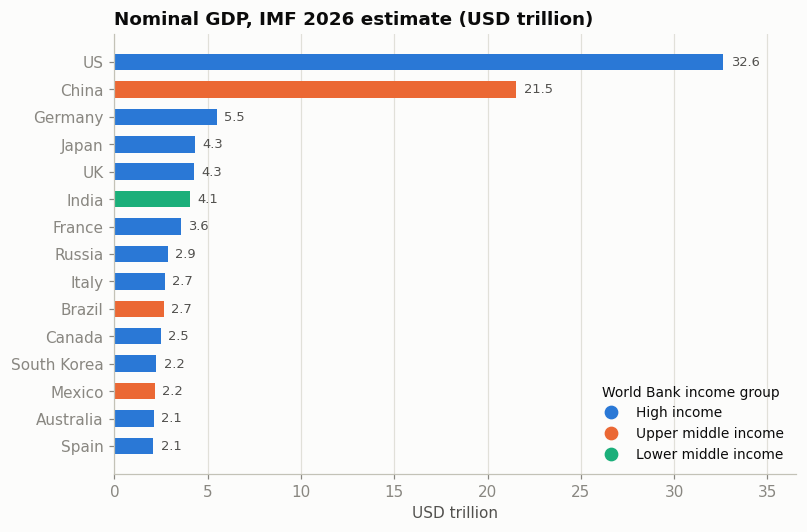

In [19]:
fig, ax = plt.subplots(figsize=(8, 5.2))
hbar(ax, df["gdp_nominal_usd_bn"] / 1000, "Nominal GDP, IMF 2026 estimate (USD trillion)", fmt="{:,.1f}", colors=gcolor, xlabel="USD trillion")
group_legend(ax, loc="lower right")
save(fig, "01_gdp_nominal")
plt.show()

### 9.2 Nominal vs PPP GDP per capita

Same unit (USD) on one axis. The gap between the two markers is how much cheaper local prices make a dollar go, so a long gap means nominal GDP understates living standards.

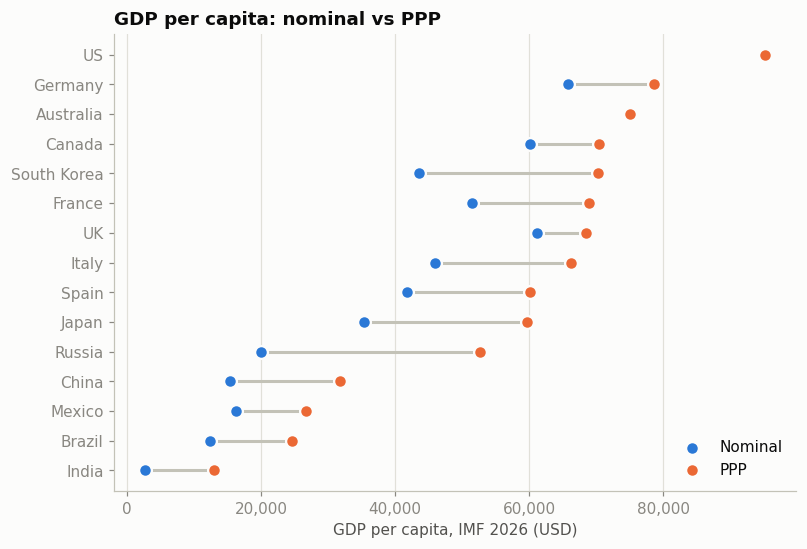

In [20]:
order = df["gdp_pc_ppp_usd"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 5.4))
y = np.arange(len(order))
ax.hlines(y, df.loc[order, "gdp_pc_nominal_usd"], df.loc[order, "gdp_pc_ppp_usd"], color=BASE, lw=2, zorder=1)
ax.scatter(df.loc[order, "gdp_pc_nominal_usd"], y, s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=2, label="Nominal")
ax.scatter(df.loc[order, "gdp_pc_ppp_usd"], y, s=70, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=2, label="PPP")
ax.set_yticks(y, [short(c) for c in order])
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("GDP per capita, IMF 2026 (USD)")
ax.set_title("GDP per capita: nominal vs PPP")
ax.legend(loc="lower right")
save(fig, "02_gdp_per_capita")
plt.show()

### 9.3 Trade

**Read the balance as approximate.** Exports come from Wikipedia's exports list (World Bank goods and services, year 2025 per its Year column). Imports come from the imports list (World Bank goods and services, retrieved September 2025) and that table has no year column, so it is probably a year older. The balance subtracts one from the other and divides by IMF 2026 GDP in USD, so small balances (a point or two of GDP) can be artefacts of vintage and exchange rates. Only large, consistent gaps should be taken at face value.

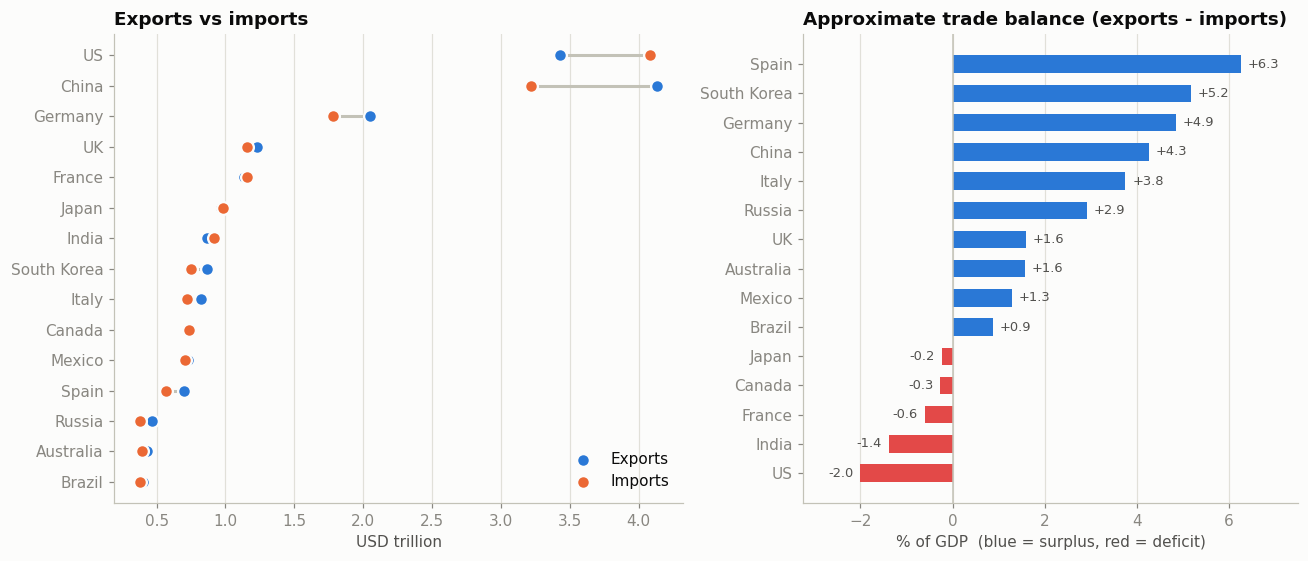

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
order = df["exports_usd_bn"].add(df["imports_usd_bn"]).sort_values().index
y = np.arange(len(order))
ax1.hlines(y, df.loc[order, "imports_usd_bn"] / 1000, df.loc[order, "exports_usd_bn"] / 1000, color=BASE, lw=2, zorder=1)
ax1.scatter(df.loc[order, "exports_usd_bn"] / 1000, y, s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=2, label="Exports")
ax1.scatter(df.loc[order, "imports_usd_bn"] / 1000, y, s=70, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=2, label="Imports")
ax1.set_yticks(y, [short(c) for c in order])
ax1.grid(axis="y", visible=False)
ax1.set_xlabel("USD trillion")
ax1.set_title("Exports vs imports")
ax1.legend(loc="lower right")

tb = df["trade_balance_pct_gdp"].dropna().sort_values()
ax2.barh([short(c) for c in tb.index], tb.values, height=0.6, color=[BLUE if v >= 0 else RED for v in tb.values])
ax2.axvline(0, color=BASE, lw=1)
ax2.grid(axis="y", visible=False)
for i, v in enumerate(tb.values):
    ax2.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
ax2.set_xlabel("% of GDP  (blue = surplus, red = deficit)")
ax2.set_title("Approximate trade balance (exports - imports)")
ax2.margins(x=0.15)
fig.tight_layout()
save(fig, "03_trade")
plt.show()

### 9.4 Development: income vs human development

Bubble area is population. Income is on a log scale because it spans more than an order of magnitude.

label placement: France could not be placed without overlap; using least-overlapping slot


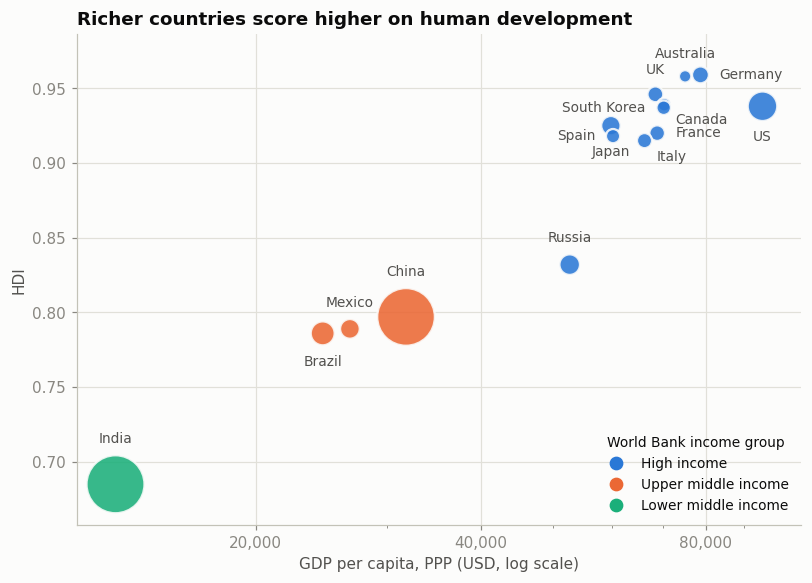

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 5.8))
sizes = df["population_m"] / df["population_m"].max() * 1400 + 40
ax.scatter(df["gdp_pc_ppp_usd"], df["hdi"], s=sizes, c=gcolor, alpha=0.88, edgecolor=SURFACE, linewidth=1.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xticks([10_000, 20_000, 40_000, 80_000])
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("GDP per capita, PPP (USD, log scale)")
ax.set_ylabel("HDI")
ax.set_title("Richer countries score higher on human development")
ax.margins(x=0.06, y=0.1)
group_legend(ax, loc="lower right")
annotate_points(ax, df["gdp_pc_ppp_usd"], df["hdi"], radius_pt=np.sqrt(sizes) / 2)
save(fig, "04_income_vs_hdi")
plt.show()

### 9.5 Macro: growth vs inflation, and the four macro gauges

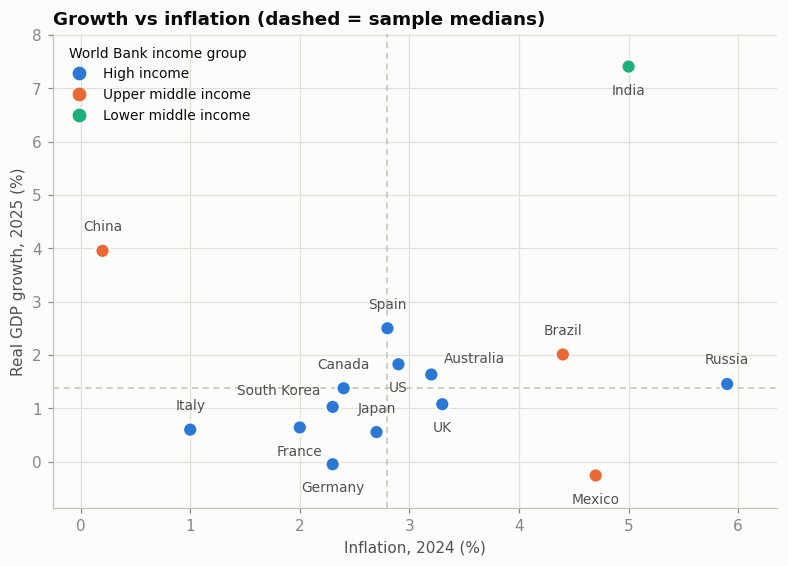

In [23]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
ax.scatter(df["inflation_pct"], df["gdp_growth_pct"], s=90, c=gcolor, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axhline(df["gdp_growth_pct"].median(), color=BASE, lw=1, ls=(0, (4, 3)))
ax.axvline(df["inflation_pct"].median(), color=BASE, lw=1, ls=(0, (4, 3)))
ax.set_xlabel(f"Inflation, {int(years['inflation_pct'].dropna().iloc[0])} (%)")
ax.set_ylabel(f"Real GDP growth, {int(years['gdp_growth_pct'].dropna().iloc[0])} (%)")
ax.set_title("Growth vs inflation (dashed = sample medians)")
ax.margins(0.08)
group_legend(ax, loc="upper left")
annotate_points(ax, df["inflation_pct"], df["gdp_growth_pct"])
save(fig, "05_growth_vs_inflation")
plt.show()

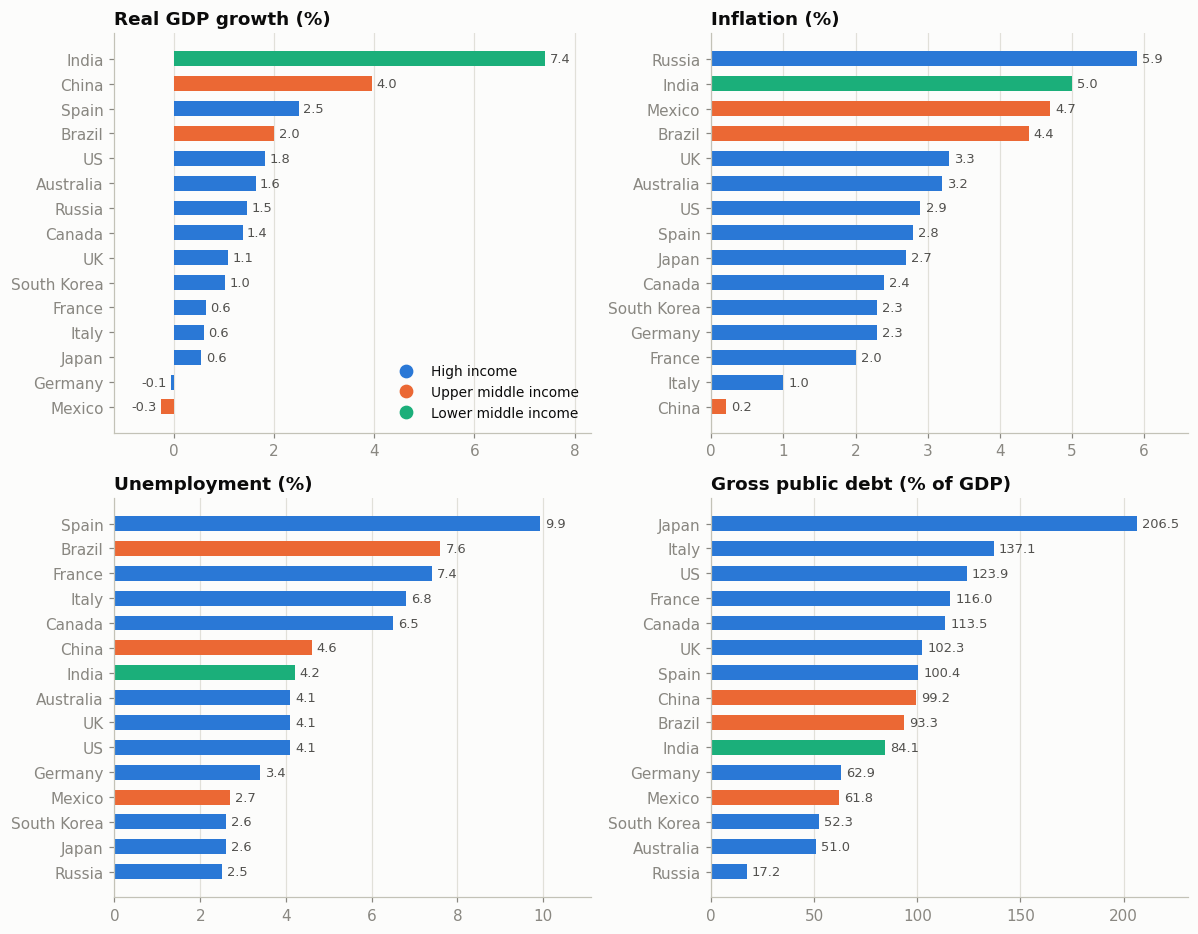

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.6))
panels = [("gdp_growth_pct", "Real GDP growth (%)"), ("inflation_pct", "Inflation (%)"),
          ("unemployment_pct", "Unemployment (%)"), ("public_debt_pct_gdp", "Gross public debt (% of GDP)")]
for ax, (k, title) in zip(axes.ravel(), panels):
    hbar(ax, df[k], title, colors=gcolor)
group_legend(axes[0, 0], loc="lower right", title=None)
fig.tight_layout()
save(fig, "06_macro_gauges")
plt.show()

### 9.6 Poverty and inequality

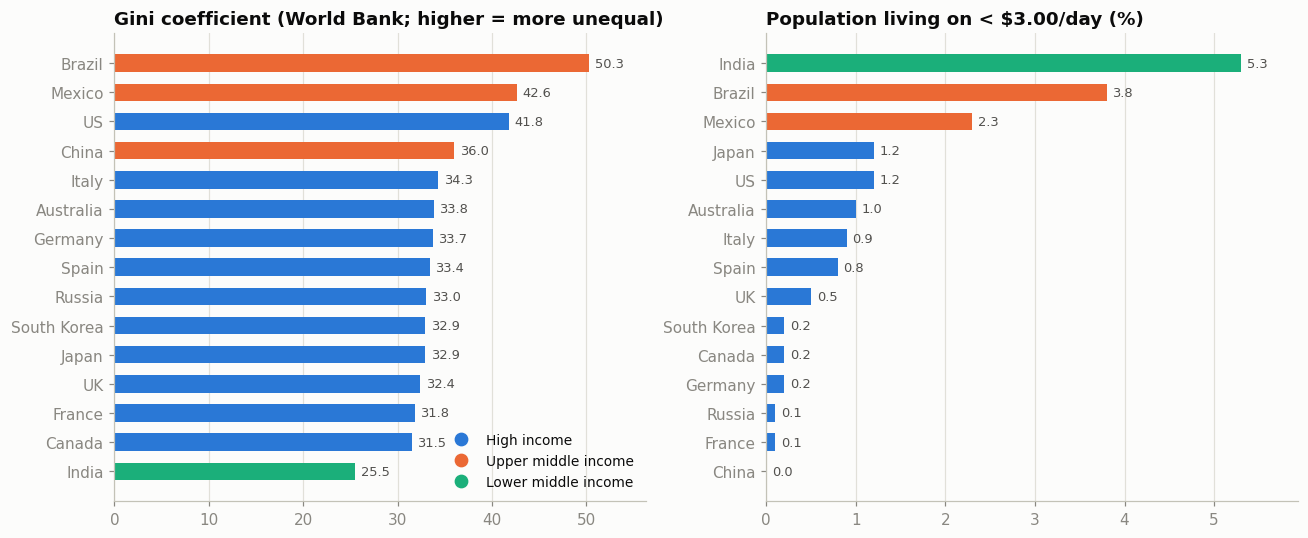

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
hbar(ax1, df["gini_wb"], "Gini coefficient (World Bank; higher = more unequal)", colors=gcolor)
hbar(ax2, df["poverty_3usd_pct"], "Population living on < $3.00/day (%)", colors=gcolor)
group_legend(ax1, loc="lower right", title=None)
fig.tight_layout()
save(fig, "07_inequality_poverty")
plt.show()

### 9.7 Demography: age structure and growth

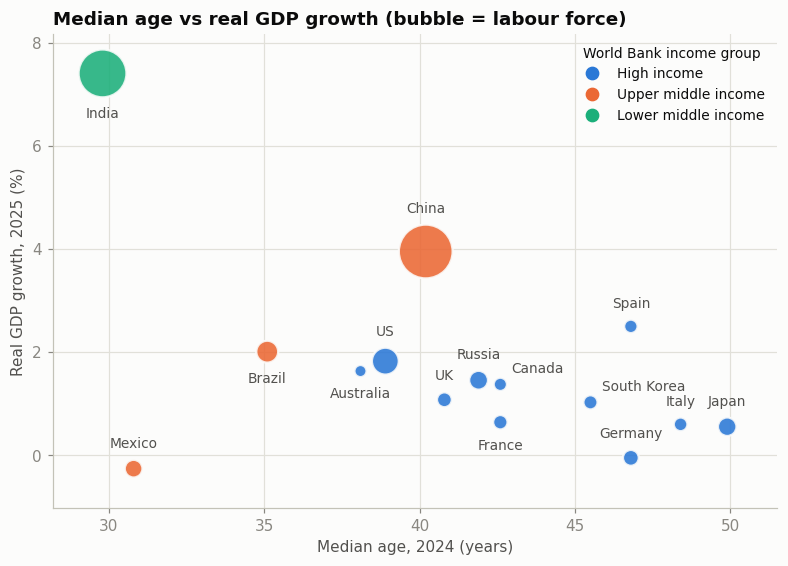

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
size = df["labour_force_m"] / df["labour_force_m"].max() * 1200 + 40
ax.scatter(df["median_age"], df["gdp_growth_pct"], s=size, c=gcolor, alpha=0.88, edgecolor=SURFACE, linewidth=1.5)
ax.set_xlabel("Median age, 2024 (years)")
ax.set_ylabel("Real GDP growth, 2025 (%)")
ax.set_title("Median age vs real GDP growth (bubble = labour force)")
ax.margins(x=0.08, y=0.1)
group_legend(ax, loc="upper right")
annotate_points(ax, df["median_age"], df["gdp_growth_pct"], radius_pt=np.sqrt(size) / 2)
save(fig, "08_age_vs_growth")
plt.show()

### 9.8 Relationships and scorecard

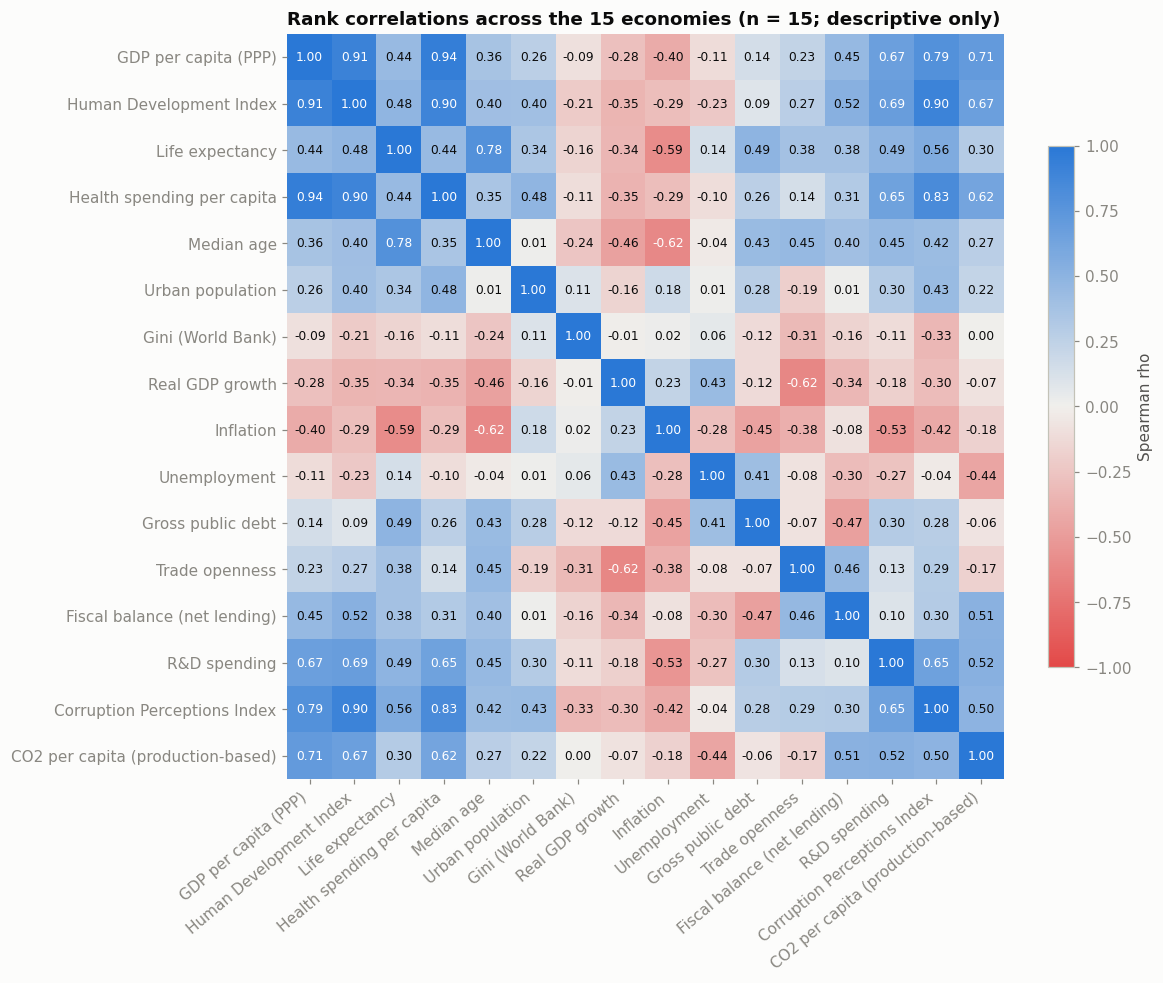

In [27]:
def heat(ax, values, rows, cols, fmt="{:.2f}", vlim=1.0):
    im = ax.imshow(values, cmap=DIVERGING, vmin=-vlim, vmax=vlim, aspect="auto")
    ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right")
    ax.set_yticks(range(len(rows)), rows)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            if np.isnan(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=8, color=MUTED)
            else:
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                        color="white" if abs(v) > 0.6 * vlim else INK)
    return im


fig, ax = plt.subplots(figsize=(10.5, 8.8))
labels = [META[k]["label"] for k in CORR_KEYS]
im = heat(ax, corr.values, labels, labels)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman rho")
ax.set_title("Rank correlations across the 15 economies (n = 15; descriptive only)")
save(fig, "09_correlations")
plt.show()

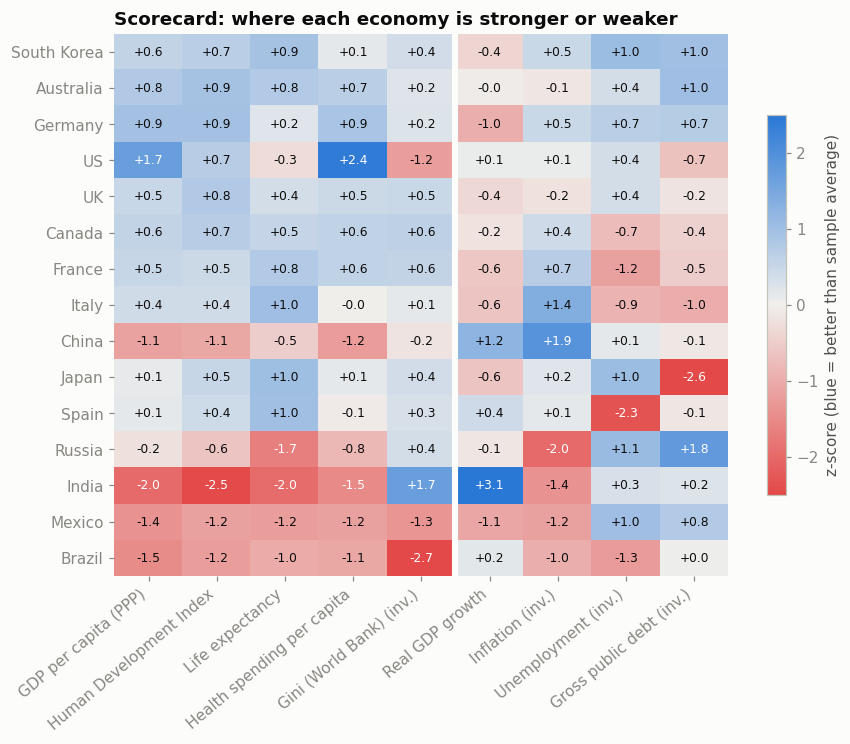

In [28]:
score_keys = list(PROSPERITY) + list(MACRO)
Z = pd.concat([z_pros, z_macro], axis=1)[score_keys]
order = (df["prosperity_index"] + df["macro_index"]).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 6.4))
col_labels = [META[k]["label"] + (" (inv.)" if (PROSPERITY | MACRO)[k] < 0 else "") for k in score_keys]
im = heat(ax, Z.loc[order].values, [short(c) for c in order], col_labels, fmt="{:+.1f}", vlim=2.5)
ax.axvline(len(PROSPERITY) - 0.5, color=SURFACE, lw=4)
fig.colorbar(im, ax=ax, shrink=0.7, label="z-score (blue = better than sample average)")
ax.set_title("Scorecard: where each economy is stronger or weaker")
save(fig, "10_scorecard")
plt.show()

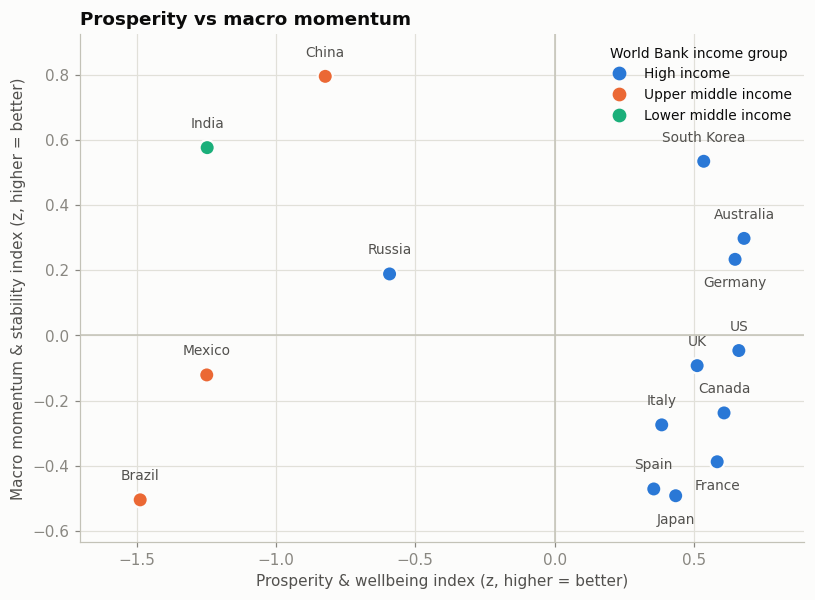

In [29]:
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(df["prosperity_index"], df["macro_index"], s=100, c=gcolor, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axhline(0, color=BASE, lw=1)
ax.axvline(0, color=BASE, lw=1)
ax.set_xlabel("Prosperity & wellbeing index (z, higher = better)")
ax.set_ylabel("Macro momentum & stability index (z, higher = better)")
ax.set_title("Prosperity vs macro momentum")
ax.margins(0.1)
group_legend(ax, loc="upper right")
annotate_points(ax, df["prosperity_index"], df["macro_index"])
save(fig, "11_two_index_scatter")
plt.show()

### 9.9 Profile of three contrasting economies

Radar axes are min-max scaled across the 15 countries (1 = best in the sample; indicators where lower is better are inverted). Three series only, to keep the colours distinguishable.

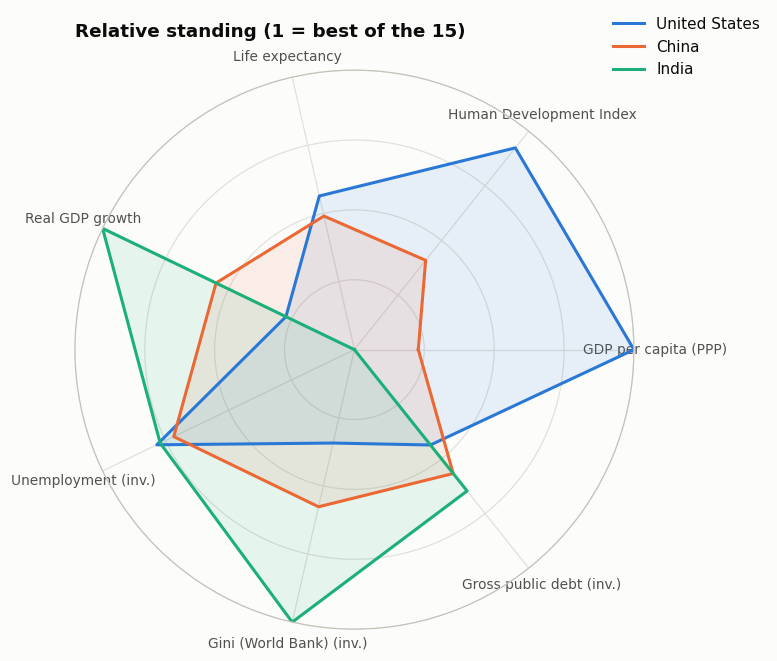

In [30]:
RADAR = {"gdp_pc_ppp_usd": +1, "hdi": +1, "life_expectancy": +1, "gdp_growth_pct": +1,
         "unemployment_pct": -1, "gini_wb": -1, "public_debt_pct_gdp": -1}
scaled = pd.DataFrame({k: ((df[k] - df[k].min()) / (df[k].max() - df[k].min())) if s > 0
                       else ((df[k].max() - df[k]) / (df[k].max() - df[k].min())) for k, s in RADAR.items()})
spokes = [META[k]["label"] + (" (inv.)" if s < 0 else "") for k, s in RADAR.items()]
angles = np.linspace(0, 2 * np.pi, len(RADAR), endpoint=False).tolist()

fig = plt.figure(figsize=(7.4, 6.6))
ax = fig.add_subplot(111, polar=True)
for country, color in zip(["United States", "China", "India"], [BLUE, ORANGE, AQUA]):
    vals = scaled.loc[country].tolist()
    ax.plot(angles + angles[:1], vals + vals[:1], color=color, lw=2, label=country)
    ax.fill(angles + angles[:1], vals + vals[:1], color=color, alpha=0.10)
ax.set_xticks(angles, spokes, fontsize=9, color=INK2)
ax.set_yticks([0.25, 0.5, 0.75, 1.0], ["", "", "", ""])
ax.set_ylim(0, 1)
ax.grid(color=GRID)
ax.spines["polar"].set_color(BASE)
ax.set_title("Relative standing (1 = best of the 15)", pad=22)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.12))
save(fig, "12_radar_us_china_india")
plt.show()

### 9.10 External position

Three views of financial exposure. Years differ by indicator (reserves are 2024 to 2026 reports, the current account is 2023, external debt is mostly 2025 to 2026), so read these as rough orders of magnitude. External debt is gross and includes financial-sector and intra-group borrowing, which inflates financial centres such as the UK and France.

**Reserves caveat:** the column used is "including gold", and gold is valued inconsistently. The US figure is only about 11 bn USD above its ex-gold figure, which is what 8,133 tonnes is worth at the historical book price of 42.22 USD an ounce, whereas Germany's gap (about 266 bn USD) reflects market value. At market prices the US figure would be far higher, so the US bar understates its reserves, and the import-cover months likewise. The ex-gold column is not used because Wikipedia leaves it blank for some countries.

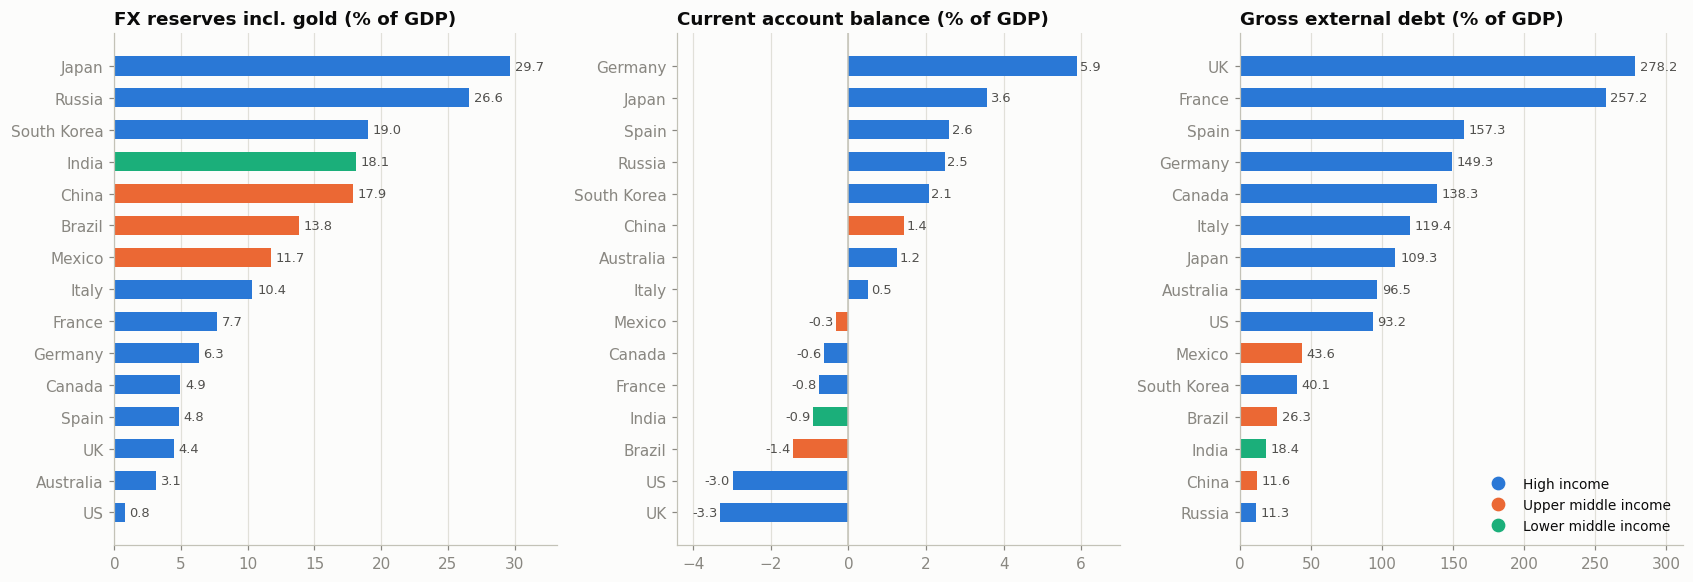

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4))
hbar(axes[0], df["reserves_pct_gdp"], "FX reserves incl. gold (% of GDP)", colors=gcolor)
hbar(axes[1], df["current_account_pct_gdp"], "Current account balance (% of GDP)", colors=gcolor)
axes[1].axvline(0, color=BASE, lw=1)
hbar(axes[2], df["ext_debt_pct_gdp"], "Gross external debt (% of GDP)", colors=gcolor)
group_legend(axes[2], loc="lower right", title=None)
fig.tight_layout()
save(fig, "13_external_position")
plt.show()

### 9.11 Public finances

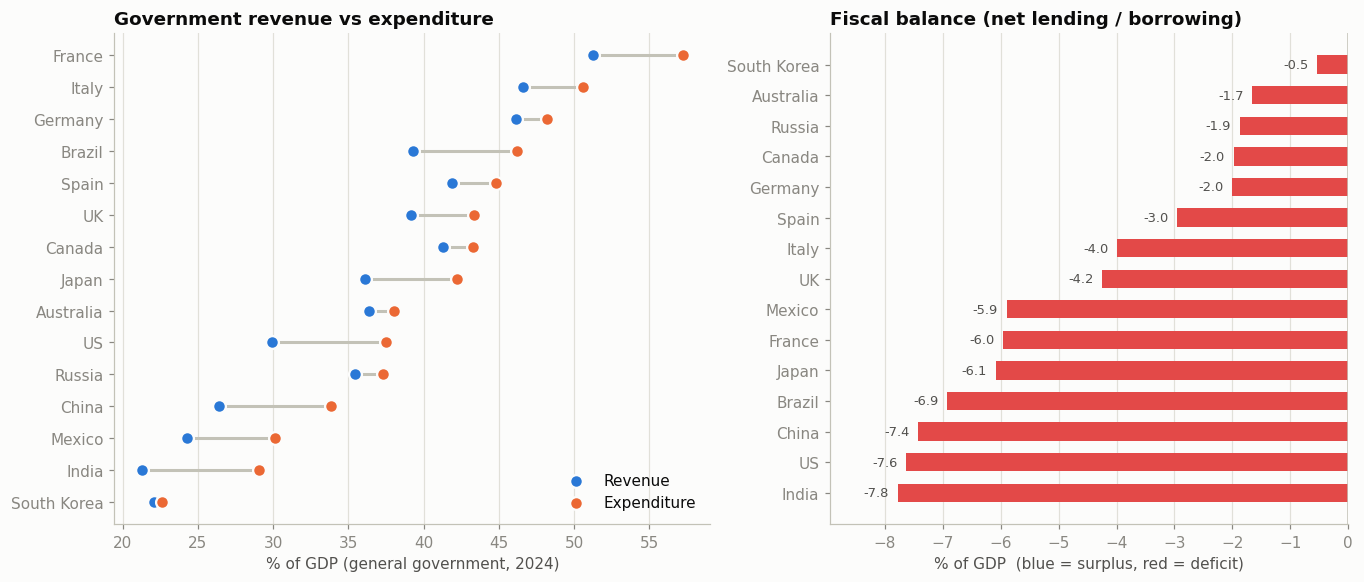

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
order = df["gov_expenditure_pct_gdp"].sort_values().index
y = np.arange(len(order))
ax1.hlines(y, df.loc[order, "gov_revenue_pct_gdp"], df.loc[order, "gov_expenditure_pct_gdp"], color=BASE, lw=2, zorder=1)
ax1.scatter(df.loc[order, "gov_revenue_pct_gdp"], y, s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=2, label="Revenue")
ax1.scatter(df.loc[order, "gov_expenditure_pct_gdp"], y, s=70, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=2, label="Expenditure")
ax1.set_yticks(y, [short(c) for c in order])
ax1.grid(axis="y", visible=False)
ax1.set_xlabel("% of GDP (general government, 2024)")
ax1.set_title("Government revenue vs expenditure")
ax1.legend(loc="lower right")

fb = df["fiscal_balance_pct_gdp"].dropna().sort_values()
ax2.barh([short(c) for c in fb.index], fb.values, height=0.6, color=[BLUE if v >= 0 else RED for v in fb.values])
ax2.axvline(0, color=BASE, lw=1)
ax2.grid(axis="y", visible=False)
for i, v in enumerate(fb.values):
    ax2.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
ax2.set_xlabel("% of GDP  (blue = surplus, red = deficit)")
ax2.set_title("Fiscal balance (net lending / borrowing)")
ax2.margins(x=0.15)
fig.tight_layout()
save(fig, "14_public_finances")
plt.show()

### 9.12 Economic structure

Shares of GDP by sector, as reported on Wikipedia (the page does not state a year, and its totals appear to be around 2024). Shares may not sum to exactly 100% because of unallocated items.

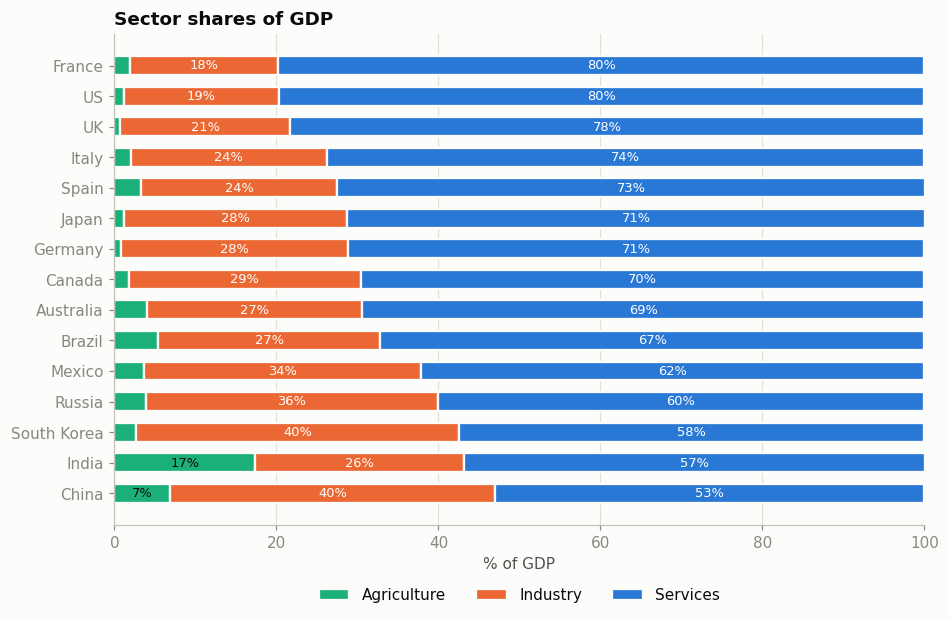

In [33]:
order = df["sector_services_pct"].sort_values().index
parts = [("sector_agriculture_pct", AQUA, "Agriculture", INK), ("sector_industry_pct", ORANGE, "Industry", "white"),
         ("sector_services_pct", BLUE, "Services", "white")]
fig, ax = plt.subplots(figsize=(9.5, 5.8))
left = np.zeros(len(order))
for key, color, label, text_color in parts:
    w = df.loc[order, key].values
    ax.barh([short(c) for c in order], w, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=1.5, label=label)
    for i, (l, v) in enumerate(zip(left, w)):
        if v >= 6:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color=text_color)
    left = left + w
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% of GDP")
ax.set_title("Sector shares of GDP")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
save(fig, "15_economic_structure")
plt.show()

### 9.13 Innovation and governance versus income

label placement: Russia could not be placed without overlap; using least-overlapping slot


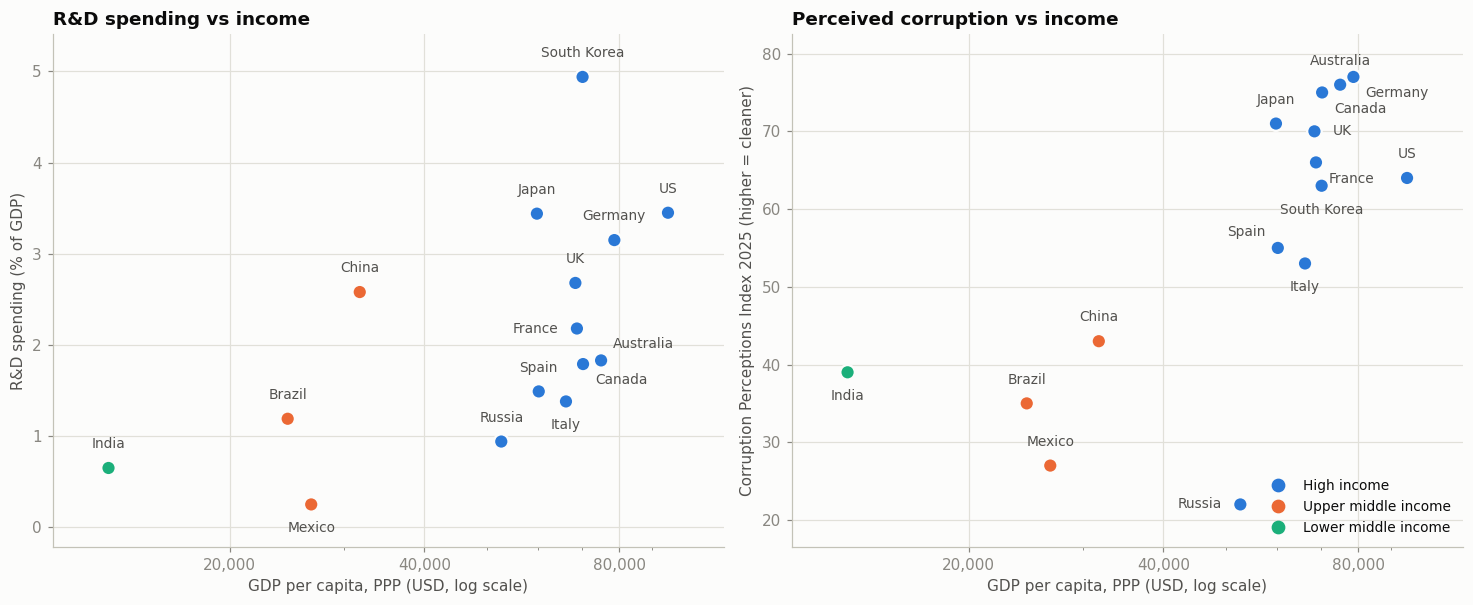

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6))
for ax, key, ylabel, title in [(ax1, "rnd_pct_gdp", "R&D spending (% of GDP)", "R&D spending vs income"),
                               (ax2, "cpi_score", "Corruption Perceptions Index 2025 (higher = cleaner)", "Perceived corruption vs income")]:
    ax.scatter(df["gdp_pc_ppp_usd"], df[key], s=90, c=gcolor, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.set_xscale("log")
    ax.set_xticks([10_000, 20_000, 40_000, 80_000])
    ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xlabel("GDP per capita, PPP (USD, log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.margins(0.1)
group_legend(ax2, loc="lower right", title=None)
annotate_points(ax1, df["gdp_pc_ppp_usd"], df["rnd_pct_gdp"])
annotate_points(ax2, df["gdp_pc_ppp_usd"], df["cpi_score"])
fig.tight_layout()
save(fig, "16_innovation_governance")
plt.show()

### 9.14 Carbon footprint

Production-based CO2 per person (2021, from Wikipedia's per-capita page, the only CO2 table that lists France, Italy and Spain separately) and a derived intensity: kilograms of CO2 per PPP dollar of GDP per capita. The intensity divides 2021 emissions by an IMF 2026 income estimate, so it is a rough comparison, not a precise measurement.

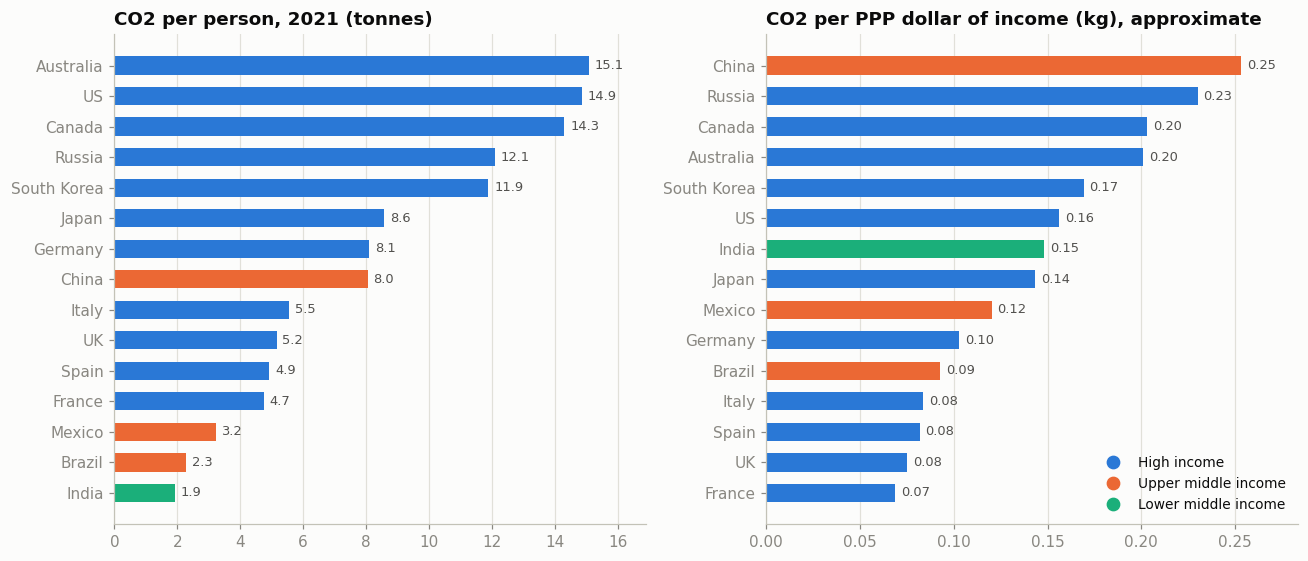

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2))
hbar(ax1, df["co2_per_capita_t"], "CO2 per person, 2021 (tonnes)", colors=gcolor)
hbar(ax2, df["co2_per_ppp_gdp_kg"], "CO2 per PPP dollar of income (kg), approximate", fmt="{:,.2f}", colors=gcolor)
group_legend(ax2, loc="lower right", title=None)
fig.tight_layout()
save(fig, "17_carbon")
plt.show()

## 10. Insights and conclusions

All figures below are from the cleaned snapshot (`data/clean/economic_indicators.csv`). Correlations are Spearman rank correlations over **15 countries**, so they describe patterns in this sample and do not show cause and effect.

### What the data shows

1. **Output is highly concentrated.** The 15 economies hold 74.4% of world nominal GDP (IMF 2026 estimate). The US (32.6 tn USD, 25.5% of world GDP) and China (21.5 tn, 16.8%) together make up 57% of the sample's GDP. Germany is a distant third at 5.5 tn, and positions 4 to 6 (Japan, UK, India) sit within 0.3 tn of each other.

2. **Nominal GDP understates the large emerging economies.** On a PPP basis China (44.6 tn) is larger than the US and India (19.2 tn) is third. PPP GDP is 4.7x nominal GDP for India, 2.6x for Russia, 2.1x for China and 2.0x for Brazil, against roughly 1.0x to 1.2x for the US, Australia, the UK, Canada and Germany. Per person, the PPP ranking still has the US first (95k USD), then Germany (79k) and Australia (75k), with India last (13k).

3. **Income and human development move together.** GDP per capita (PPP) has a rank correlation of 0.91 with HDI and 0.94 with health spending per capita. Life expectancy tracks median age most closely (0.78) rather than income (0.44). Japan (84.0 years), Italy (84.0) and Spain (83.9) lead on life expectancy, despite being well below the US on income. The US is the outlier on health spending (12,434 PPP USD per person, the highest by far, against 273 in India) while having a life expectancy of 78.9, below Canada, Australia, Japan, South Korea and all of Germany, the UK, France, Italy and Spain (each above 80).

4. **Growth is fastest at the low-income end, but the relationship is weak.** India (7.4%) and China (4.0%) lead 2025 real growth, and Germany (-0.05%) and Mexico (-0.3%) are the only contractions. The rank correlation between income and growth is only -0.28: Mexico is lower-income and shrank, Spain (2.5%) is high-income and grew faster than most. Younger populations show only a weak tendency to grow faster (median age vs growth: -0.46, which falls to -0.34 without India and -0.29 without India and China), so I would not call it a pattern. Trade openness shows a stronger negative link with growth (-0.62), but openness is mechanically lower for large domestic markets (US 23%, Brazil and Russia 30%), so I would not read much into it.

5. **Fiscal and labour-market risks are in the old, rich economies.** Seven economies have gross public debt above 100% of GDP: Japan (206.5%), Italy (137.1%), the US (123.9%), France, Canada, the UK and Spain. Russia (17.2%) is the only economy under 50%; Australia (51.0%) and South Korea (52.3%) are next lowest. Unemployment is highest in Spain (9.9%), Brazil (7.6%) and France (7.4%), and lowest in Russia, Japan and South Korea (2.5% to 2.6%). Inflation is highest in Russia (5.9%), India (5.0%), Mexico (4.7%) and Brazil (4.4%), and lowest in China (0.2%) and Italy (1.0%).

6. **Trade dependence differs sharply.** South Korea (72%), Germany (70%) and Mexico (66%) have exports plus imports of goods and services equal to about two-thirds of GDP or more, while the US (23%) is the least trade-dependent. In level terms China is the biggest exporter (4.1 tn USD) and the US the biggest importer (4.1 tn). The US shows a deficit (about -2% of GDP) while China (+4%) and Germany (+5%) show surpluses. *Treat these balances as approximate, see the caveats.*

7. **Inequality and poverty are worst in Latin America.** Brazil has the highest Gini by far (50.3), then Mexico (42.6) and the US (41.8). Extreme poverty (below 3.00 USD a day) is 5.3% in India, 3.8% in Brazil and 2.3% in Mexico, and at most 1.2% everywhere else. National poverty lines are not comparable across countries: they are set relative to local living standards, which is why the UK (21.0%) and Spain (20.2%) report rates similar to India (23.9%).

8. **No economy leads on everything.** In the two-index scorecard only South Korea, Australia and Germany are above the sample average on both prosperity and macro stability and momentum. The US ranks second on prosperity (0.66) but is just below average on the macro index (-0.05) because of high debt and slower growth. China and India lead on the macro index (0.79 and 0.58) but sit in the bottom half on prosperity. Brazil is last on both (-1.49 prosperity, -0.50 macro).

9. **External balance sheets differ more than output does.** China holds the largest FX reserves (3.9 tn USD), then Japan (1.3 tn) and Russia (0.8 tn); relative to GDP, Japan (29.7%) and Russia (26.6%) lead, and the lowest are the US (0.8%, but see the gold note at the end of this item), Australia (3.1%) and the UK (4.4%). The current account (2023) is in surplus for Germany (+5.9% of GDP), Japan (+3.6%) and Spain (+2.6%) and in deficit for the UK (-3.3%) and the US (-3.0%). The economies with the least external debt are also reserve-rich economies: Russia (11.3% of GDP), China (11.6%) and India (18.4%). The highest are the UK (278%) and France (257%), which are financial centres whose gross figures include a lot of financial-sector borrowing. The US reserves figure (0.8% of GDP) is understated because Wikipedia values its gold at historical book price.

10. **Every one of the 15 ran a fiscal deficit in 2024.** The largest were India (-7.8% of GDP), the US (-7.6%) and China (-7.4%); the smallest were South Korea (-0.5%), Australia (-1.7%) and Russia (-1.9%). Governments differ far more in size than in balance: France collects 51.3% of GDP in revenue and spends 57.2%, while India collects 21.3% and South Korea 22.1%. High debt does not always mean a big deficit: Italy (debt 137%) ran -4.0%, while India (debt 84%) ran -7.8%.

11. **Services dominate every economy, but industry still anchors a few.** Services are about 80% of GDP in France and the US and 78% in the UK, against 53% in China, 57% in India and 58% in South Korea. Industry is the biggest share in China (40.1%), South Korea (39.8%) and Russia (36.0%). Agriculture is 17.4% of GDP in India and 6.9% in China, and no more than 5.4% in any of the others.

12. **Innovation spending and perceived corruption both rise with income, with exceptions.** R&D is highest in South Korea (4.9% of GDP), the US (3.5%) and Japan (3.4%), and lowest in Mexico (0.25%), India (0.65%, 2020) and Russia (0.9%). China spends 2.6% of GDP on R&D, more than France (2.2%) or Australia (1.8%), though its income per person is less than half theirs. On the Corruption Perceptions Index (2025), Germany (77), Australia (76) and Canada (75) score cleanest and Russia (22), Mexico (27) and Brazil (35) lowest; the rank correlation with HDI is 0.90 and with income 0.79. The US (64) scores lower than six of the richer economies (Germany, Australia, Canada, Japan, the UK and France).

13. **Carbon: income buys emissions, but not equally.** Per person, Australia (15.1 t), the US (14.9 t) and Canada (14.3 t) emit the most and India (1.9 t) and Brazil (2.3 t) the least (2021, rank correlation with income 0.71). China (8.0 t) already emits about the same per person as Germany (8.1 t), on roughly 40% of Germany's income. Per unit of income, China (0.25 kg of CO2 per PPP dollar) and Russia (0.23) are the most carbon-intensive and France (0.07), the UK, Italy and Spain (0.08 each) the least. The data here cannot say why (energy mix is not in it), and the intensity figure divides 2021 emissions by a 2026 income estimate, so treat the gaps between close countries as noise.

### Caveats

* **Snapshot, not a trend.** Every value is the latest one Wikipedia shows, so data years differ by indicator (see `indicator_provenance.csv`): GDP, GDP per capita and PPP are IMF 2026 estimates, growth is an IMF estimate for 2025, inflation and unemployment are 2024, population is 2023, HDI is 2023, life expectancy and median age are 2024, government finances are 2024, the current account is 2023, reserves are 2024 to 2026 reports, external debt is mostly 2025 to 2026 (Mexico 2023), R&D is 2020 to 2024 (India 2020, Australia 2021), perceived corruption is 2025 and CO2 is 2021. The sector shares have no stated year on Wikipedia (their GDP totals look like 2024). Nothing here says how any economy is changing over time.
* **Trade balance is approximate.** Exports (World Bank, 2025) and imports (World Bank, retrieved September 2025, no year column) are probably from different years, and both are divided by an IMF 2026 GDP estimate in USD. Balances of a point or two of GDP, such as the UK (+1.6%) or Spain (+6.3%), could be artefacts. The US deficit and the China and Germany surpluses are large enough to be credible.
* **Gaps and fills.** Russia's 2024 inflation was missing from the list page and was filled from its "Economy of Russia" infobox (5.9%, a 2025 value). The US national poverty rate (10.6%, 2024) was filled the same way. National poverty rates for Japan and Brazil stay missing: Brazil's infobox only gives a rate against an international 8.30 USD/day line, which would not be comparable.
* **Gini is not like-for-like.** India's World Bank Gini (25.5) is consumption-based and is not comparable with income-based figures; UNU-WIDER's income-based value is 37.1. The `gini_unu_wider` column is in the dataset for that reason, but the scorecard uses the World Bank column, so it flatters India on prosperity.
* **The scorecard does not use the newer indicators.** It was built before reserves, finances, structure, R&D, corruption and CO2 were added and I left it unchanged, so its results (and the paragraph above on it) are about the original set. Adding them would be a judgement call about which of them count as "better".
* **The scorecard is a judgement call.** Equal weights, a hand-picked set of components, and z-scores over only 15 countries (one outlier moves a score a lot). Use it to organise the comparison, not as a ranking.
* **Wikipedia is a secondary source.** Values depend on editors keeping tables current, and some sources differ (IMF 2026 nominal GDP is 0.98x to 1.20x the World Bank 2025 figure across the 15 countries, partly because one is a projection and one an actual). Spot-check anything you plan to rely on against the original source.
* **Not included.** FDI was in the original plan "if consistently available"; the FDI-inflows page parses for all 15 countries but I have not added it. The CO2 page's totals fold France, Italy and Spain into one EU row, so the per-person production-based table is used instead. Adult literacy is scraped and saved but not analysed further: it only separates India (74.4%), Brazil (93.2%) and Mexico (95.2%) from the rest, and Wikipedia shows a round 99.0% for seven of the others.